# Modelos não lineares e MCMC — da posterior ao algoritmo
**Igor Stellet · Estatística Bayesiana · 2026.2**

Nos modelos lineares gaussianos, a matriz de precisão fornecia tanto o melhor ajuste quanto a posterior completa. Agora a distribuição pode ter assimetrias, faixas curvas e vários modos. Precisamos escolher **como procurar os máximos, calcular integrais e gerar amostras**, e depois avaliar a qualidade numérica dos resultados.

O notebook tem o seguinte follow up:

1. Comparar malha, Monte Carlo, Fisher, DALI e nested sampling em exemplos pequenos.
2. Encontrar máximos: busca global, annealing, algoritmo genético e Levenberg–Marquardt.
3. Construir uma cadeia de Markov e demonstrar a regra de aceitação de Metropolis–Hastings.
4. Reproduzir os dois exemplos dos slides e investigar proposta, burn-in e autocorrelação.
5. Deduzir e acompanhar o diagnóstico de Gelman–Rubin, incluindo a esperança de seus estimadores.
6. Implementar simulated tempering e conectar o estudo às práticas de grid, Cobaya e emcee.

In [1]:
from pathlib import Path
from time import perf_counter
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special, integrate, optimize, linalg
from IPython.display import display, Markdown

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':220,'font.size':11,
    'axes.titlesize':12,'legend.fontsize':9,'grid.alpha':.2,
    'axes.spines.top':False,'axes.spines.right':False,'pdf.fonttype':42})
AZUL,VERDE,OURO,ROXO,VERMELHO='#2878B5','#27856D','#B58618','#8055A3','#BD5254'
SALVAR_ARQUIVOS=False
BASE=Path.cwd();PF=BASE/'figuras'/'capitulo_11_MCMC';PT=BASE/'tabelas'/'capitulo_11_MCMC'
checks,figuras=[],[]
def verificar(nome,condicao):
    if not np.all(condicao):raise AssertionError(nome)
    checks.append(nome)
def figura(fig,nome):
    figuras.append(nome)
    if SALVAR_ARQUIVOS:
        PF.mkdir(parents=True,exist_ok=True)
        for ext in ('png','pdf'):fig.savefig(PF/f'{nome}.{ext}',bbox_inches='tight')
    plt.show();plt.close(fig)
def tabela(df,nome=None,casas=5):
    display(df.round(casas))
    if SALVAR_ARQUIVOS and nome:
        PT.mkdir(parents=True,exist_ok=True);df.to_csv(PT/f'{nome}.csv',index=False)
def pesos_trapezio(v):
    v=np.asarray(v);w=np.empty(len(v));w[0]=(v[1]-v[0])/2;w[-1]=(v[-1]-v[-2])/2
    w[1:-1]=(v[2:]-v[:-2])/2
    return w

def metropolis(logp,inicio,n,escala=1.,seed=0,proposta=None,logq=None,guardar_propostas=False):
    """MH homogêneo; n inclui o estado inicial; rejeições repetem o estado."""
    rng=np.random.default_rng(seed);atual=np.atleast_1d(inicio).astype(float)
    dim=len(atual);lp=float(logp(atual))
    if not np.isfinite(lp):raise ValueError('O estado inicial deve ter densidade positiva.')
    s=np.asarray(escala)
    L=np.eye(dim)*float(s) if s.ndim==0 else (np.diag(s) if s.ndim==1 else np.linalg.cholesky(s))
    cadeia=np.empty((n,dim));logs=np.empty(n);aceitou=np.zeros(n,dtype=bool)
    candidatos=np.empty((n,dim)) if guardar_propostas else None
    cadeia[0]=atual;logs[0]=lp
    if candidatos is not None:candidatos[0]=atual
    for t in range(1,n):
        novo=atual+L@rng.normal(size=dim) if proposta is None else np.atleast_1d(proposta(atual,rng))
        lnovo=float(logp(novo));logr=lnovo-lp
        if logq is not None:logr+=float(logq(atual,novo)-logq(novo,atual))
        if np.log(rng.random())<min(0.,logr):
            atual=novo.copy();lp=lnovo;aceitou[t]=True
        cadeia[t]=atual;logs[t]=lp
        if candidatos is not None:candidatos[t]=novo
    return {'chain':cadeia,'logp':logs,'accepted':aceitou,
            'acceptance':aceitou[1:].mean(),'proposals':candidatos}

def acf_fft(valores,max_lag=None):
    """ACF com normalização por lag zero; padding evita convolução circular."""
    a=np.asarray(valores,float);a=a-a.mean();n=len(a)
    if np.all(a==0):return np.ones(min(n,max_lag+1 if max_lag is not None else n))
    tamanho=1<<(2*n-1).bit_length();f=np.fft.rfft(a,n=tamanho)
    c=np.fft.irfft(f*f.conj(),n=tamanho)[:n];rho=c/c[0]
    return rho if max_lag is None else rho[:max_lag+1]
def tau_integrado(valores):
    """Janela inicial de pares positivos de autocorrelações (estimador didático)."""
    rho=acf_fft(valores);soma=0.;janela=0
    for h in range(1,len(rho)-1,2):
        par=rho[h]+rho[h+1]
        if par<=0:break
        soma+=par;janela=h+1
    return max(1.,1+2*soma),janela

def gelman_rubin(cadeias):
    """Fórmula escalar dos slides; entrada (M,N). Sem truncar R em 1."""
    c=np.asarray(cadeias,float);M,N=c.shape
    if M<2 or N<2:raise ValueError('Precisamos de pelo menos duas cadeias e dois passos.')
    medias=c.mean(axis=1);s2=c.var(axis=1,ddof=1).mean();Sigma2=medias.var(ddof=1)
    V=(N-1)/N*s2+Sigma2;R2=V/s2
    return {'s2':s2,'Sigma2':Sigma2,'V':V,'R2':R2,'R':np.sqrt(R2)}
def rhat_rank_split(cadeias):
    """Complemento moderno: máximo entre split-Rhat de ranks e de ranks dobrados."""
    c=np.asarray(cadeias,float);M,N=c.shape;h=N//2
    split=np.concatenate([c[:,:h],c[:,-h:]],axis=0)
    def rank_normal(a):
        ranks=stats.rankdata(a.ravel(),method='average')
        return stats.norm.ppf((ranks-.375)/(a.size+.25)).reshape(a.shape)
    r1=gelman_rubin(rank_normal(split))['R']
    folded=np.abs(split-np.median(split))
    r2=gelman_rubin(rank_normal(folded))['R']
    return max(r1,r2)

print('Exportação opcional:',SALVAR_ARQUIVOS)

Exportação opcional: False


## 1. Três tarefas que costumam aparecer juntas

Definimos a posterior alvo e a evidência:
$$
\pi(\theta)=p(\theta\mid D)=\frac{\mathcal L(D\mid\theta)p(\theta)}{Z},
\qquad Z=\int\mathcal L(D\mid\theta)p(\theta)\,d\theta.
$$
**Otimizar** procura um máximo dessa função. **Integrar** calcula massas, médias, marginais e $Z$. **Amostrar** produz pontos cuja frequência representa a massa da posterior, permitindo estimar integrais. Um máximo estreito pode conter menos probabilidade que uma região larga de densidade menor.

| Método | Princípio | Vantagem | Custo ou limite importante |
|---|---|---|---|
| Malha (*grid*) | Avaliar a função numa grade e somar volumes | Transparência; referência em poucas dimensões | $K^d$ avaliações para $K$ valores em cada um de $d$ parâmetros |
| Monte Carlo / importância | Médias de avaliações aleatórias, com pesos adequados | Integrais sem grade completa | A eficiência depende da sobreposição entre proposta e integrando |
| Fisher | Aproximação quadrática da log-posterior | Muito rápida perto de um pico regular | Geometria local elipsoidal |
| DALI | Reter mais derivadas do modelo dentro da forma gaussiana dos dados | Pode representar degenerescências curvas | Requer derivadas e hipóteses de construção; será aprofundado depois |
| MCMC | Cadeia com distribuição estacionária igual à posterior | Concentra o cálculo em regiões relevantes | Mistura, autocorrelação e modos separados determinam o custo |
| Nested sampling | Integrar a likelihood ordenada pelo volume de prior | Evidência e posterior ponderada | Amostrar regiões de likelihood restrita é a etapa difícil |

A dimensão sozinha deixa parte da dificuldade escondida. Para MCMC, o custo relevante depende do custo por avaliação e de quantas avaliações produzem informação efetivamente nova; **uma lei universal $d\log d$ para o algoritmo completo precisa de hipóteses adicionais**. O número de parâmetros viável para uma malha depende também da resolução e do custo do modelo.

### 1.1 Malha: retomando a prática do Mathematica

Usamos a função da prática, com prior constante no retângulo explicitado:
$$
\widetilde\pi(x,y)=
\exp\left[-\left(\frac{x-2}{4}\right)^2
          -\left(\frac{y-0{,}03x^2}{2{,}4}\right)^4\right].
$$
Os números definem um exemplo matemático; seu objetivo é investigar uma distribuição curva. Para uma grade, o ponto $(x_i,y_j)$ representa uma pequena área $w_iw_j$. Sua massa aproximada é
$$
m_{ij}=\frac{\widetilde\pi_{ij}w_iw_j}{\sum_{kl}\widetilde\pi_{kl}w_kw_l}.
$$
A densidade se normaliza por uma integral; a soma das **massas** vale 1. Para encontrar uma região HPD de probabilidade $P$, ordenamos as células por densidade decrescente e acumulamos suas massas até $P$. A marginal em $x$ resulta da soma em $y$, incluindo os pesos de integração. Repetir o cálculo em malhas mais finas permite conferir o erro de discretização.

,Pontos por eixo,Integral não normalizada,Média de x
0,41,30.84171,1.99892
1,101,30.84182,1.99894
2,241,30.84184,1.99894


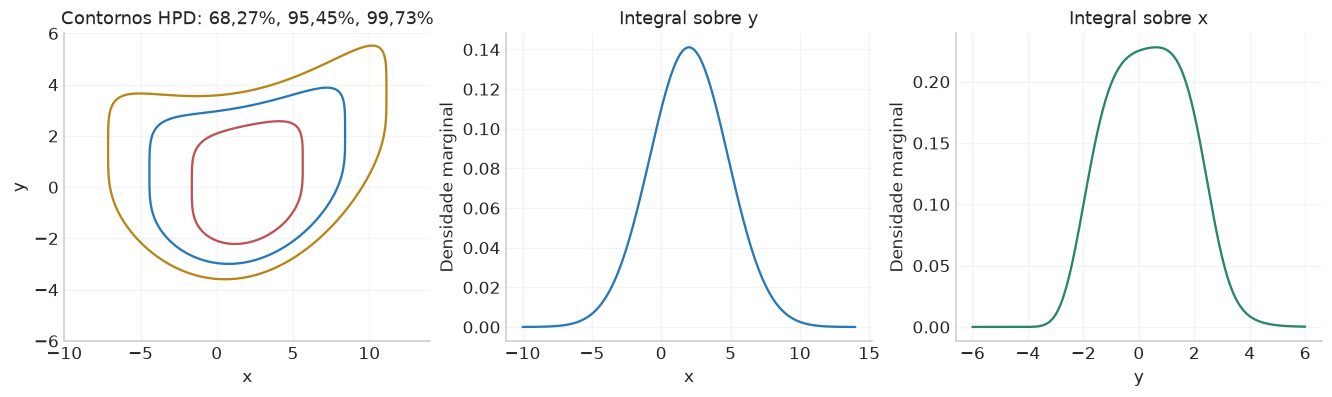

In [2]:
def log_grid_class(x,y):return -((x-2)/4)**2-((y-.03*x**2)/2.4)**4
def analisar_grid(n):
    xv=np.linspace(-10,14,n);yv=np.linspace(-6,6,n)
    X,Y=np.meshgrid(xv,yv,indexing='ij');raw=np.exp(log_grid_class(X,Y))
    wx,wy=pesos_trapezio(xv),pesos_trapezio(yv);volume=np.outer(wx,wy)
    Z=np.sum(raw*volume);pdf=raw/Z;mass=pdf*volume
    ordem=np.argsort(-pdf.ravel());acum=np.cumsum(mass.ravel()[ordem])
    levels=[pdf.ravel()[ordem[min(np.searchsorted(acum,p),len(ordem)-1)]] for p in [.6827,.9545,.9973]]
    px=pdf@wy;py=wx@pdf
    return xv,yv,pdf,mass,Z,np.array(levels),px,py
res_grid=[analisar_grid(n) for n in [41,101,241]]
xg,yg,pg,mg,Zg,niveis,px,py=res_grid[-1]
tabela(pd.DataFrame({'Pontos por eixo':[41,101,241],'Integral não normalizada':[r[4] for r in res_grid],
    'Média de x':[np.sum(r[0]*r[6]*pesos_trapezio(r[0])) for r in res_grid]}),'grid_refinamento')
fig,ax=plt.subplots(1,3,figsize=(12,3.5),constrained_layout=True)
ax[0].contour(xg,yg,pg.T,levels=np.sort(niveis),colors=[OURO,AZUL,VERMELHO])
ax[0].set(xlabel='x',ylabel='y',title='Contornos HPD: 68,27%, 95,45%, 99,73%')
ax[1].plot(xg,px,color=AZUL);ax[1].set(xlabel='x',ylabel='Densidade marginal',title='Integral sobre y')
ax[2].plot(yg,py,color=VERDE);ax[2].set(xlabel='y',ylabel='Densidade marginal',title='Integral sobre x')
figura(fig,'01_grid_pratica')
verificar('Normalização da malha',np.isclose(mg.sum(),1))
verificar('Refinamento da integral da malha',abs(res_grid[-1][4]/res_grid[-2][4]-1)<.002)

### 1.2 Monte Carlo: transformar uma integral em uma média

Se $U_i$ são independentes e uniformes em um volume $V$, sua densidade é $1/V$. Então
$$
I=\int_Vg(\theta)d\theta=V\,\mathbb E[g(U)],
\quad \widehat I=\frac{V}{n}\sum_{i=1}^n g(U_i),
\quad\operatorname{Var}(\widehat I)=\frac{V^2}{n}\operatorname{Var}[g(U)].
$$
Com variância finita, o erro padrão estimado é $Vs_g/\sqrt n$. O número $n$ conta avaliações aleatórias e pode crescer mantendo os mesmos dados observados.

Para importância, escolhemos uma densidade $q$ positiva onde o integrando contribui:
$$
I=\mathbb E_q[g(\theta)/q(\theta)].
$$
Se $g=\mathcal Lp$ e queremos $\mathbb E_\pi[f]$, podemos usar pesos $w_i=\mathcal L(\theta_i)p(\theta_i)/q(\theta_i)$ e a razão
$\sum w_if(\theta_i)/\sum w_i$. A versão auto-normalizada é consistente sob condições usuais, com possível viés para $n$ finito.

No exemplo seguinte, calculamos $I=\int_{-8}^8e^{-x^2/2}dx$. A proposta $q=\mathcal N(0,1)$ acompanha exatamente a forma do integrando; ela é uma escolha deliberadamente ideal para tornar visível a diferença de eficiência.

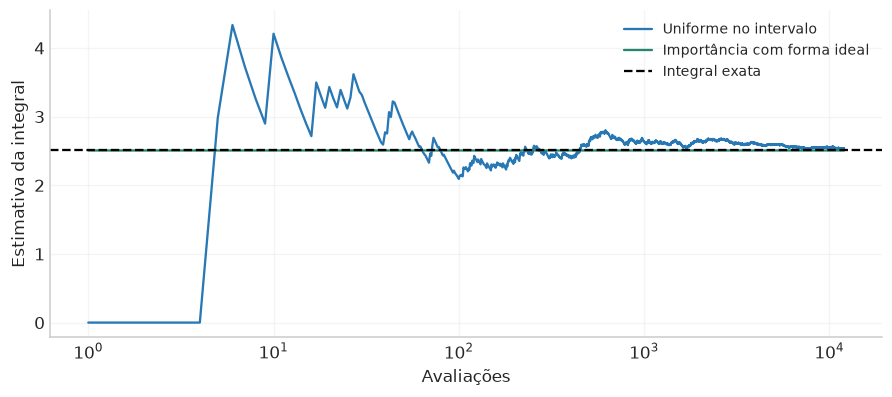

,Método,Integral estimada,Erro padrão estimado
0,Uniforme,2.53617,0.04321
1,Importância ideal,2.50663,0.00000


In [3]:
rng=np.random.default_rng(1101);n_mc=12000
u=rng.uniform(-8,8,n_mc);a=16*np.exp(-u*u/2)
v=rng.normal(size=n_mc);b=np.sqrt(2*np.pi)*(np.abs(v)<=8)
I_exato=np.sqrt(2*np.pi)*(stats.norm.cdf(8)-stats.norm.cdf(-8))
fig,ax=plt.subplots(figsize=(8,3.5),constrained_layout=True)
ax.plot(np.arange(1,n_mc+1),np.cumsum(a)/np.arange(1,n_mc+1),color=AZUL,label='Uniforme no intervalo')
ax.plot(np.arange(1,n_mc+1),np.cumsum(b)/np.arange(1,n_mc+1),color=VERDE,label='Importância com forma ideal')
ax.axhline(I_exato,color='black',ls='--',label='Integral exata');ax.set(xscale='log',xlabel='Avaliações',ylabel='Estimativa da integral');ax.legend()
figura(fig,'02_monte_carlo_importancia')
tabela(pd.DataFrame({'Método':['Uniforme','Importância ideal'],'Integral estimada':[a.mean(),b.mean()],
    'Erro padrão estimado':[a.std(ddof=1)/np.sqrt(n_mc),b.std(ddof=1)/np.sqrt(n_mc)]}),'mc_importancia')

### 1.3 Fisher e uma primeira ideia de DALI

Considere dados gaussianos $D=(0,0)$ com erros independentes de desvios $(1,s)$ e modelo
$\mu(u,v)=(u,v-\kappa u^2)$. Aqui $u,v$ são os parâmetros, $\kappa$ controla a curvatura da previsão e $E=\operatorname{diag}(1,s^2)$ é a matriz de covariância dos dados. Com prior plana,
$$
\widetilde\pi(u,v)=\exp[-\tfrac12\{u^2+(v-\kappa u^2)^2/s^2\}].
$$
Fisher lineariza a previsão em $(0,0)$: $\delta\mu\simeq(u,v)$, produzindo elipses. Uma construção do tipo **DALI de segunda ordem no modelo**, com covariância fixa e dados iguais à previsão fiducial, conserva
$$
\delta\mu\simeq J\delta\theta+\tfrac12\mu_{,\alpha\beta}\delta\theta_\alpha\delta\theta_\beta,
\qquad
\log\mathcal L_{\rm DALI}\simeq-\tfrac12\delta\mu^TE^{-1}\delta\mu.
$$
Nesta expressão, $\delta\theta=(u,v)$ é o deslocamento em relação ao ponto fiducial $(0,0)$, $J_{i\alpha}=\partial\mu_i/\partial\theta_\alpha$ é o Jacobiano nesse ponto e $\mu_{,\alpha\beta}$ reúne as derivadas segundas da previsão. Somamos sobre os índices repetidos $\alpha,\beta$. Expandimos a previsão antes de calcular a distância quadrática ponderada por $E^{-1}$.

O termo ao quadrado gera os acoplamentos cúbicos e quárticos necessários à faixa curva. **Neste modelo quadrático específico**, reter as derivadas segundas de $\mu$ recupera exatamente a previsão e a likelihood. Isso serve como introdução ao princípio; a construção e as limitações gerais de DALI ficam para o bloco posterior do curso. A prior deve ser aplicada à aproximação de likelihood escolhida.

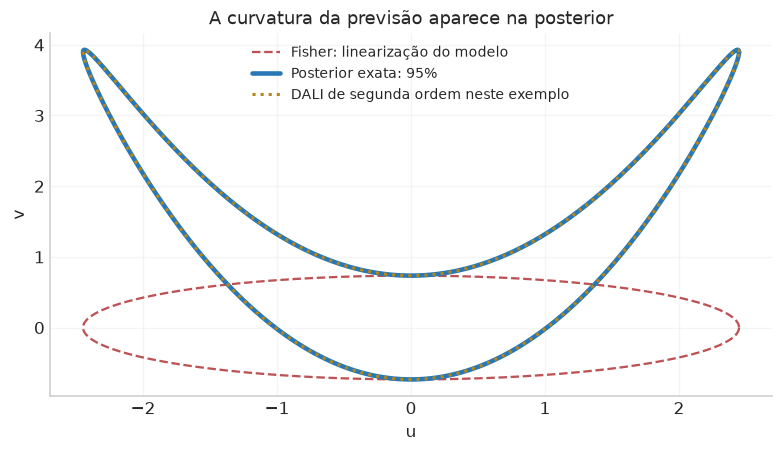

In [4]:
s_dali,kappa=.30,.65
ang=np.linspace(0,2*np.pi,700);rad=np.sqrt(stats.chi2.ppf(.95,2))
u95=rad*np.cos(ang);v95=s_dali*rad*np.sin(ang)
fig,ax=plt.subplots(figsize=(7,4),constrained_layout=True)
ax.plot(u95,v95,color=VERMELHO,ls='--',label='Fisher: linearização do modelo')
ax.plot(u95,v95+kappa*u95**2,color=AZUL,lw=3,label='Posterior exata: 95%')
ax.plot(u95,v95+kappa*u95**2,color=OURO,ls=':',lw=2,label='DALI de segunda ordem neste exemplo')
ax.set(xlabel='u',ylabel='v',title='A curvatura da previsão aparece na posterior');ax.legend()
figura(fig,'03_fisher_dali_introducao')

### 1.4 Nested sampling: ordenar a integral pelo volume da prior

Definimos $X(\ell)=\int_{\mathcal L(\theta)>\ell}p(\theta)d\theta$, a fração da prior acima de um limiar de likelihood. Ordenar as regiões dessa maneira transforma a evidência em
$$
Z=\int_0^1\mathcal L(X)\,dX.
$$
Mantemos $n_{\rm live}$ pontos distribuídos na prior restrita. A cada etapa, retiramos o ponto de menor likelihood e o substituímos por outro com likelihood maior. O fator de redução do volume tem distribuição $t\sim\operatorname{Beta}(n_{\rm live},1)$; assim, $\mathbb E[\log t]=-1/n_{\rm live}$. Uma aproximação didática é $X_i=e^{-i/n_{\rm live}}$, com
$$
\widehat Z\simeq\sum_i\mathcal L_i(X_{i-1}-X_i)
+X_{\rm final}\overline{\mathcal L}_{\rm live}.
$$
Os pontos descartados também representam a posterior, com pesos proporcionais às parcelas da evidência. Na prática, o grande desafio é gerar corretamente o novo ponto dentro da região restrita, que pode ser multimodal.

Vamos usar $d=0$, erro gaussiano conhecido $\sigma=1$ e prior uniforme $\theta\in[-8,8]$. A restrição de likelihood é um intervalo conhecido, então podemos amostrar nele exatamente. Usaremos a trajetória média de contração para mostrar a ideia; um programa científico de nested sampling também estima a incerteza na contração e trata regiões restritas gerais.

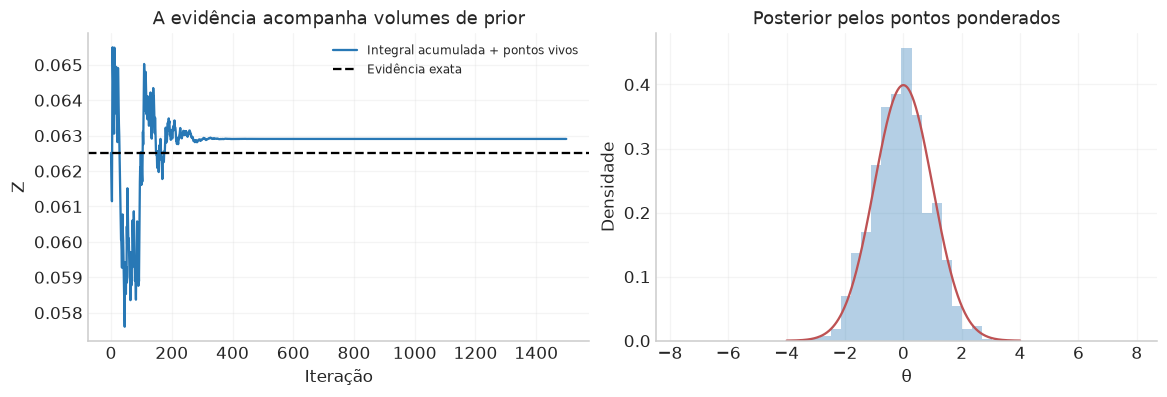

Z exata = 0.062500; nested didático = 0.062906.


In [5]:
rng_ns=np.random.default_rng(1102);nlive=120;niter=1500
live=rng_ns.uniform(-8,8,nlive);Xprev=1.;zs=[];dead=[];weights=[]
Zpartial=0.
for it in range(1,niter+1):
    j=np.argmax(np.abs(live));theta=live[j];ell=stats.norm.pdf(theta)
    Xnow=np.exp(-it/nlive);weight=ell*(Xprev-Xnow)
    dead.append(theta);weights.append(weight);Zpartial+=weight
    # L(new)>L(dead) equivale a |new|<|dead| nesta likelihood.
    live[j]=rng_ns.uniform(-abs(theta),abs(theta))
    zs.append(Zpartial+Xnow*np.mean(stats.norm.pdf(live)));Xprev=Xnow
ns_samples=np.r_[dead,live];ns_weights=np.r_[weights,np.full(nlive,Xprev/nlive)*stats.norm.pdf(live)]
Z_ns=ns_weights.sum();Z_ns_exato=(stats.norm.cdf(8)-stats.norm.cdf(-8))/16
fig,ax=plt.subplots(1,2,figsize=(10.5,3.5),constrained_layout=True)
ax[0].plot(zs,color=AZUL,label='Integral acumulada + pontos vivos');ax[0].axhline(Z_ns_exato,color='black',ls='--',label='Evidência exata')
ax[0].set(xlabel='Iteração',ylabel='Z',title='A evidência acompanha volumes de prior');ax[0].legend(fontsize=8)
ax[1].hist(ns_samples,bins=45,weights=ns_weights/Z_ns,density=True,alpha=.35,color=AZUL)
xx=np.linspace(-4,4,500);ax[1].plot(xx,stats.norm.pdf(xx),color=VERMELHO)
ax[1].set(xlabel='θ',ylabel='Densidade',title='Posterior pelos pontos ponderados')
figura(fig,'04_nested_sampling_didatico')
print(f'Z exata = {Z_ns_exato:.6f}; nested didático = {Z_ns:.6f}.')
verificar('Nested sampling encontra a escala da evidência',abs(Z_ns/Z_ns_exato-1)<.3)

## 2. Encontrar o best fit: busca global e aproximação local

Com prior plana e $E$ fixa, maximizar a posterior equivale a minimizar $\chi^2$. Com prior informativa, o objetivo para o MAP é
$$
\Phi(\theta)=-\log\mathcal L(D\mid\theta)-\log p(\theta)+\text{constante}.
$$
Usar $\Phi=\chi^2/2$ no caso gaussiano simplifica os fatores. A altura do máximo e as regiões de probabilidade são informações complementares. Encontrar um máximo também pode ser difícil em espaços com muitos modos ou avaliações caras; uma rotina local informa o mínimo que conseguiu alcançar a partir da inicialização.

### 2.1 Uma paisagem com dois vales

Para visualizar, escolhemos $\Phi(x)=0{,}06(x^2-9)^2+0{,}35x$, no intervalo $[-6,6]$. Trata-se de um potencial adimensional ilustrativo. A inclinação favorece o vale da esquerda; uma busca local começando à direita pode terminar no outro vale.

- **Busca aleatória:** sorteia candidatos no domínio e retém o melhor. É simples, mas pode desperdiçar avaliações em regiões pouco úteis.
- **Downhill simplex / Nelder–Mead:** move um conjunto de pontos por reflexão, expansão e contração, usando apenas valores da função. É útil quando derivadas são difíceis; sua solução continua dependente do ponto de partida e da geometria.
- **Simulated annealing:** usa a distribuição auxiliar $p_T\propto e^{-\Phi/T}$. Para proposta simétrica, aceita um aumento $\Delta\Phi>0$ com probabilidade $e^{-\Delta\Phi/T}$. Temperaturas altas permitem cruzar barreiras; o resfriamento favorece os vales mais baixos.
- **Algoritmo genético:** evolui uma população por seleção, cruzamento e mutação, preservando bons candidatos. A população explora várias regiões ao mesmo tempo, com custo e desempenho dependentes desses operadores.

No Gregory §11.4, o resfriamento é descrito até $T=1$, onde se recupera a posterior original. Para **otimização**, também podemos resfriar abaixo de 1 e guardar o melhor ponto visitado. Essa trajetória com temperatura variável é uma fase de busca, e suas frequências ainda dependem do calendário de resfriamento. Para amostrar a posterior, usamos uma etapa com alvo fixo e diagnósticos próprios.

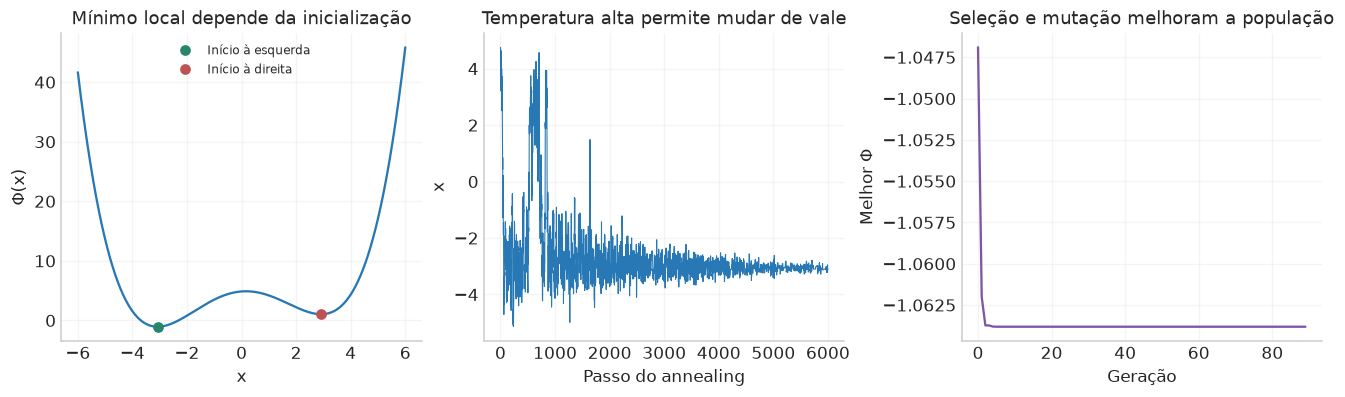

,Método,x,Φ
0,Local: esquerda,-3.07793,-1.06381
1,Local: direita,2.91543,1.03542
2,Annealing: melhor visitado,-3.07806,-1.06381
3,Genético: melhor geração,-3.07795,-1.06381


In [6]:
def energia(x):return .06*(np.asarray(x)**2-9)**2+.35*np.asarray(x)
rng_opt=np.random.default_rng(1201);xx=np.linspace(-6,6,1601)
local_esq=optimize.minimize(lambda a:float(energia(a[0])),[-4.],method='Nelder-Mead')
local_dir=optimize.minimize(lambda a:float(energia(a[0])),[4.],method='Nelder-Mead')
# Annealing implementado explicitamente.
n_sa=6000;temps=np.geomspace(6.,.03,n_sa);pos=4.;best=pos;traj=[];melhores=[]
for T in temps:
    cand=pos+rng_opt.normal(0,.65)
    if -6<cand<6 and np.log(rng_opt.random())<min(0.,-(energia(cand)-energia(pos))/T):pos=cand
    if energia(pos)<energia(best):best=pos
    traj.append(pos);melhores.append(float(energia(best)))
# Algoritmo genético real: torneio, cruzamento aritmético, mutação e elitismo.
pop=rng_opt.uniform(-6,6,64);hist_gen=[];best_gen=[]
for ger in range(90):
    valores=energia(pop);ordem=np.argsort(valores);nova=list(pop[ordem[:2]])
    hist_gen.append(float(valores.min()));best_gen.append(pop[ordem[0]])
    while len(nova)<len(pop):
        torneios=rng_opt.integers(0,len(pop),size=(2,3))
        pais=[pop[t[np.argmin(valores[t])]] for t in torneios]
        mix=rng_opt.random();filho=mix*pais[0]+(1-mix)*pais[1]
        if rng_opt.random()<.35:filho+=rng_opt.normal(0,.4)
        nova.append(np.clip(filho,-6,6))
    pop=np.array(nova)
fig,ax=plt.subplots(1,3,figsize=(12,3.5),constrained_layout=True)
ax[0].plot(xx,energia(xx),color=AZUL)
for r,cor,lab in [(local_esq,VERDE,'Início à esquerda'),(local_dir,VERMELHO,'Início à direita')]:
    ax[0].plot(r.x,energia(r.x),'o',color=cor,label=lab)
ax[0].set(xlabel='x',ylabel='Φ(x)',title='Mínimo local depende da inicialização');ax[0].legend(fontsize=8)
ax[1].plot(traj,color=AZUL,lw=.7);ax[1].set(xlabel='Passo do annealing',ylabel='x',title='Temperatura alta permite mudar de vale')
ax[2].plot(hist_gen,color=ROXO);ax[2].set(xlabel='Geração',ylabel='Melhor Φ',title='Seleção e mutação melhoram a população')
figura(fig,'05_otimizacao_global')
tabela(pd.DataFrame({'Método':['Local: esquerda','Local: direita','Annealing: melhor visitado','Genético: melhor geração'],
    'x':[local_esq.x[0],local_dir.x[0],best,best_gen[-1]],
    'Φ':[local_esq.fun,local_dir.fun,energia(best),hist_gen[-1]]}),'busca_global')
verificar('Annealing encontra vale mais baixo que a busca local direita',energia(best)<local_dir.fun)

### 2.2 Gregory §11.5: linearizar a previsão a cada iteração

Agora o exemplo tem interpretação física. Medimos a descarga de um circuito RC:
$$
f(t;A,\tau,B)=B+A e^{-t/\tau},\qquad \tau=RC>0.
$$
$A$ é a amplitude em volts, $B$ é um offset em volts e $\tau$ é a escala de tempo. As medidas simuladas seguem
$d_i=f(t_i;\theta)+\varepsilon_i$, com $\varepsilon_i\sim\mathcal N(0,\sigma^2)$ independentes e $\sigma$ conhecido.
Portanto, neste exemplo $E=\sigma^2 I$ e $W=E^{-1}=\sigma^{-2}I$; $E$ descreve os erros dos dados e $W$ atribui peso aos resíduos. A letra $I$ representa a matriz identidade.

No ponto corrente $\theta_c$, expandimos
$$
f(\theta_c+\delta)\simeq f(\theta_c)+J\delta,
\quad J_{i\alpha}=\frac{\partial f_i}{\partial\theta_\alpha},
\quad r=D-f(\theta_c).
$$
Para $\Phi=\tfrac12r^TWr$, com $W=E^{-1}$,
$$
\Phi(\theta_c+\delta)\simeq
\Phi_c-\delta^TJ^TWr+\tfrac12\delta^TJ^TWJ\delta.
$$
Derivar essa aproximação e zerar o gradiente produz o passo de **Gauss–Newton**:
$$
(J^TWJ)\delta=J^TWr.
$$
A Hessiana exata de $\Phi$ inclui ainda $-\sum_i(Wr)_if_{i,\alpha\beta}$; Gauss–Newton conserva $J^TWJ$. Próximo a um bom ajuste ou num modelo quase linear, essa aproximação pode ser apropriada.

Na expansão direta do objetivo, escrevemos
$\Phi(\theta_c+\delta)\simeq\Phi_c+g^T\delta+\tfrac12\delta^TH\delta$; seu passo de Newton satisfaz $H\delta=-g$. O fator $1/2$ exige atenção: a derivada de $\delta^T K\delta$, para $K$ simétrica, é $2K\delta$. Com a definição $K=\tfrac12\nabla^2\chi^2$ usada no livro, o gradiente da aproximação de $\chi^2$ contém $2K\delta$; a Eq. (11.26) impressa omite esse fator. Trabalhar com $\Phi=\chi^2/2$ mantém as convenções consistentes.

### 2.3 Levenberg–Marquardt: regularizar o passo

Quando a aproximação local ainda é grosseira, o passo completo pode ser grande demais. Introduzimos amortecimento:
$$
\boxed{[J^TWJ+\lambda\operatorname{diag}(J^TWJ)]\delta=J^TWr.}
$$
Para $\lambda$ grande, os passos se aproximam de um gradiente descendente reescalado em cada parâmetro. Para $\lambda\to0$, recuperamos Gauss–Newton. Aceitamos o passo quando o objetivo diminui e reduzimos $\lambda$; caso contrário aumentamos $\lambda$ e tentamos um passo mais conservador.

Neste modelo,
$$
\frac{\partial f}{\partial A}=e^{-t/\tau},\qquad
\frac{\partial f}{\partial\tau}=A\frac{t}{\tau^2}e^{-t/\tau},\qquad
\frac{\partial f}{\partial B}=1.
$$
São essas sensibilidades físicas que entram na matriz de curvatura e definem como corrigimos os parâmetros. Após encontrar o máximo e conferir a aproximação gaussiana, $C\simeq(J^TWJ)^{-1}$ fornece uma estimativa local de incertezas para a escala de ruído conhecida; uma posterior completa pode ter outra forma.

,Parâmetro,Gerador,Ajuste manual,SciPy LM,Desvio local
0,A (V),2.30,2.37352,2.37352,0.05036
1,τ (tempo),1.40,1.34114,1.34114,0.07633
2,B (V),0.25,0.24024,0.24024,0.03579


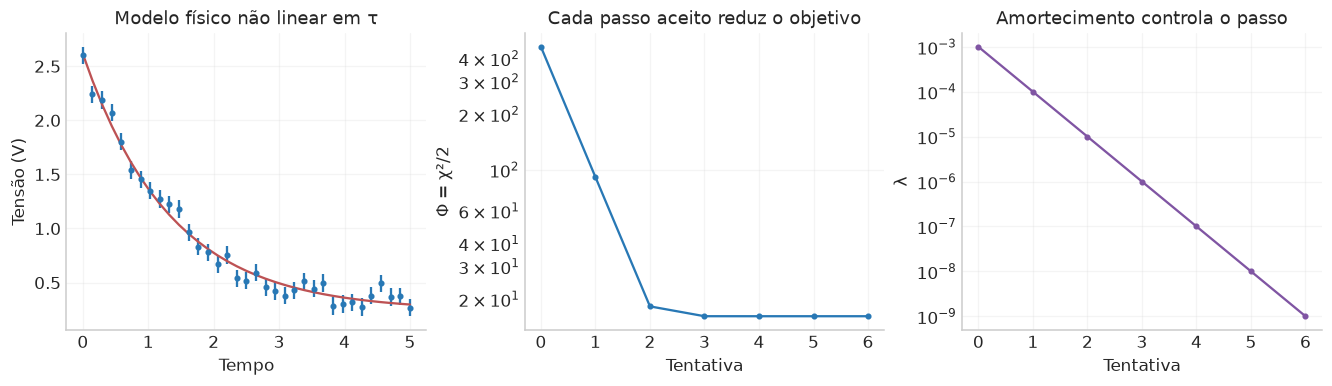

In [7]:
rng_rc=np.random.default_rng(1202);tempos=np.linspace(0,5,35);sigma_rc=.08
real_rc=np.array([2.3,1.4,.25])
def modelo_rc(theta,t=tempos):
    A,tau,B=theta;return B+A*np.exp(-t/tau)
def jac_rc(theta,t=tempos):
    A,tau,B=theta;e=np.exp(-t/tau)
    return np.column_stack([e,A*t*e/tau**2,np.ones(len(t))])
d_rc=modelo_rc(real_rc)+rng_rc.normal(0,sigma_rc,len(tempos))
def lm_manual(inicio,max_iter=100):
    theta=np.array(inicio,float);lam=1e-3;hist=[]
    for it in range(max_iter):
        r=(d_rc-modelo_rc(theta))/sigma_rc;J=jac_rc(theta)/sigma_rc
        phi=.5*r@r;H=J.T@J;h=J.T@r
        if np.linalg.norm(h,np.inf)<1e-8:break
        delta=np.linalg.solve(H+lam*np.diag(np.diag(H)),h);trial=theta+delta
        phi_trial=np.inf if trial[1]<=0 else .5*np.sum(((d_rc-modelo_rc(trial))/sigma_rc)**2)
        ok=phi_trial<phi
        hist.append([it,*theta,phi,lam,ok])
        if ok:
            theta=trial;lam=max(lam/10,1e-12)
            # Parar por mudança relativa no objetivo ou no vetor de parâmetros.
            # São tolerâncias numéricas, diferentes das incertezas físicas do ajuste.
            if phi-phi_trial<1e-10*max(1.,phi) or np.linalg.norm(delta)<1e-9*(1+np.linalg.norm(theta)):break
        else:lam=min(lam*10,1e12)
    return theta,np.array(hist)
inicio_rc=[1.2,.6,.6];fit_rc,hist_rc=lm_manual(inicio_rc)
scipy_rc=optimize.least_squares(lambda a:(modelo_rc(a)-d_rc)/sigma_rc,inicio_rc,
    jac=lambda a:jac_rc(a)/sigma_rc,method='lm')
verificar('LM manual e SciPy concordam',np.allclose(fit_rc,scipy_rc.x,rtol=1e-5,atol=1e-6))
C_rc=np.linalg.inv((jac_rc(fit_rc)/sigma_rc).T@(jac_rc(fit_rc)/sigma_rc))
tabela(pd.DataFrame({'Parâmetro':['A (V)','τ (tempo)','B (V)'],'Gerador':real_rc,
    'Ajuste manual':fit_rc,'SciPy LM':scipy_rc.x,'Desvio local':np.sqrt(np.diag(C_rc))}),'lm_rc')
fig,ax=plt.subplots(1,3,figsize=(12,3.4),constrained_layout=True)
ax[0].errorbar(tempos,d_rc,yerr=sigma_rc,fmt='o',ms=3,color=AZUL);ax[0].plot(tempos,modelo_rc(fit_rc),color=VERMELHO)
ax[0].set(xlabel='Tempo',ylabel='Tensão (V)',title='Modelo físico não linear em τ')
ax[1].semilogy(hist_rc[:,0],hist_rc[:,4],'-o',ms=3,color=AZUL);ax[1].set(xlabel='Tentativa',ylabel='Φ = χ²/2',title='Cada passo aceito reduz o objetivo')
ax[2].semilogy(hist_rc[:,0],hist_rc[:,5],'-o',ms=3,color=ROXO);ax[2].set(xlabel='Tentativa',ylabel='λ',title='Amortecimento controla o passo')
figura(fig,'06_levenberg_marquardt')

## 3. De uma caminhada aleatória a uma cadeia com alvo conhecido

Uma caminhada simples faz $X_{t+1}=X_t+\eta_t$, com incrementos independentes de média zero e variância $s^2$. Então
$$
X_t=X_0+\sum_{j=0}^{t-1}\eta_j,
\quad\mathbb E[X_t]=X_0,
\quad\operatorname{Var}(X_t)=t s^2.
$$
Sua distribuição se espalha indefinidamente na reta; essa dinâmica ainda carece de um mecanismo que estabeleça a posterior desejada como equilíbrio.

Uma cadeia de Markov obedece
$$
P(X_{t+1}\in A\mid X_t,X_{t-1},\ldots)=K(X_t,A).
$$
O **kernel de transição** $K$ fornece a probabilidade de ir do estado atual a um conjunto de próximos estados. Com kernel homogêneo, a distribuição evolui por
$\mu_{t+1}(dy)=\int\mu_t(dx)K(x,dy)$. Uma distribuição $\pi$ é estacionária se $\pi K=\pi$.

Para ilustrar, construiremos uma matriz discreta $K$ e acompanharemos diretamente $\mu_0K^t$. As linhas somam 1. Adotamos como alvo uma Poisson de média 3, temporariamente truncada em $0,\ldots,18$ para representar a matriz finita; a simulação posterior usará o suporte inteiro não negativo.

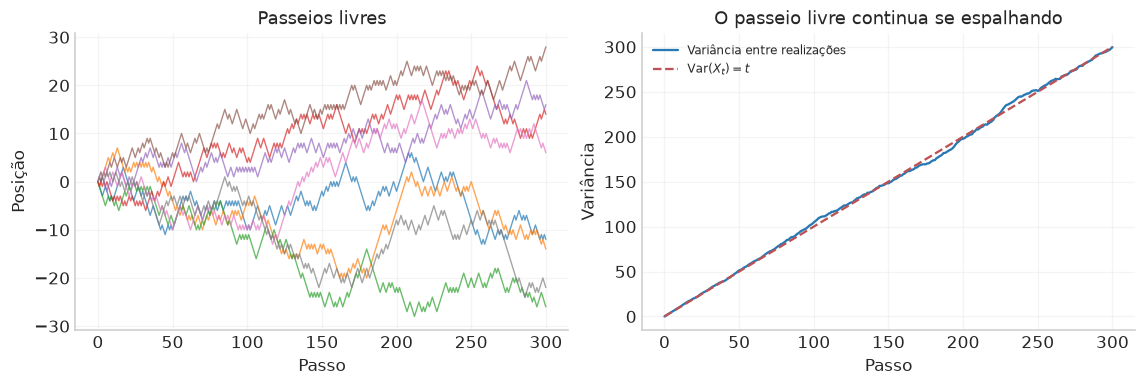

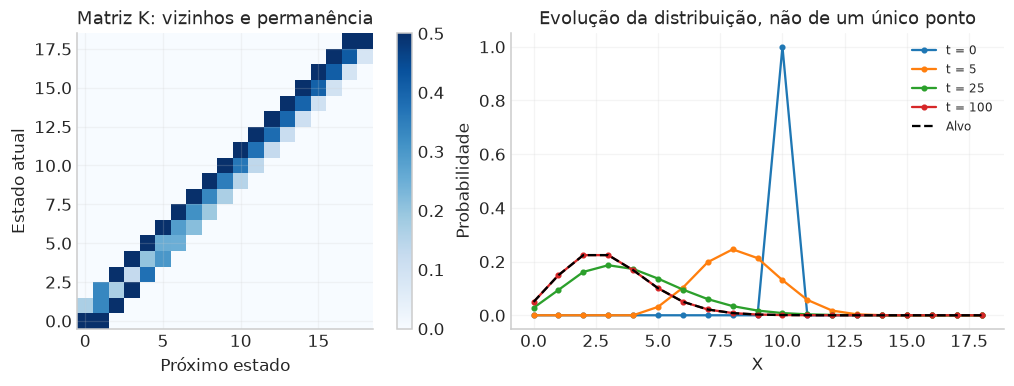

In [8]:
rng_walk=np.random.default_rng(1301);passos=rng_walk.choice([-1,1],size=(1800,300))
walk=np.c_[np.zeros(1800),np.cumsum(passos,axis=1)]
fig,ax=plt.subplots(1,2,figsize=(10.3,3.4),constrained_layout=True)
ax[0].plot(walk[:8].T,alpha=.7,lw=.9);ax[0].set(xlabel='Passo',ylabel='Posição',title='Passeios livres')
ax[1].plot(walk.var(axis=0),color=AZUL,label='Variância entre realizações');ax[1].plot(np.arange(301),'--',color=VERMELHO,label=r'$\mathrm{Var}(X_t)=t$')
ax[1].set(xlabel='Passo',ylabel='Variância',title='O passeio livre continua se espalhando');ax[1].legend(fontsize=8)
figura(fig,'07_random_walk_livre')

estados=np.arange(19);pi_p=stats.poisson.pmf(estados,3);pi_p/=pi_p.sum()
Kp=np.zeros((19,19))
for a in estados:
    for b in [a-1,a+1]:
        if 0<=b<len(estados):Kp[a,b]=.5*min(1.,pi_p[b]/pi_p[a])
    Kp[a,a]=1-Kp[a].sum()
verificar('Kernel normalizado por linha',np.allclose(Kp.sum(axis=1),1))
verificar('Balanço detalhado da matriz discreta',np.allclose(pi_p[:,None]*Kp,(pi_p[:,None]*Kp).T))
verificar('Posterior é estacionária',np.allclose(pi_p@Kp,pi_p))
fig,ax=plt.subplots(1,2,figsize=(10.3,3.4),constrained_layout=True)
im=ax[0].imshow(Kp,origin='lower',cmap='Blues');ax[0].set(xlabel='Próximo estado',ylabel='Estado atual',title='Matriz K: vizinhos e permanência');fig.colorbar(im,ax=ax[0])
mu0=np.zeros(len(estados));mu0[10]=1
for n in [0,5,25,100]:ax[1].plot(estados,mu0@np.linalg.matrix_power(Kp,n),'-o',ms=3,label=f't = {n}')
ax[1].plot(estados,pi_p,'--',color='black',label='Alvo');ax[1].set(xlabel='X',ylabel='Probabilidade',title='Evolução da distribuição, não de um único ponto');ax[1].legend(fontsize=8)
figura(fig,'08_kernel_estacionariedade')

## 4. Construir Metropolis–Hastings e demonstrar por que funciona

Queremos que a ocupação das regiões siga $\pi(\theta)$. Sabemos avaliar o numerador $\widetilde\pi=\mathcal Lp$, mesmo sem conhecer $Z$.

1. No estado $x$, sorteamos $y\sim q(y\mid x)$.
2. Aceitamos $y$ com probabilidade
$$
\boxed{\alpha(x,y)=\min\left[1,
\frac{\widetilde\pi(y)q(x\mid y)}{\widetilde\pi(x)q(y\mid x)}\right].}
$$
3. Se houver rejeição, o próximo estado é novamente $x$.

O kernel completo contém as duas possibilidades:
$$
K(x,dy)=q(y\mid x)\alpha(x,y)dy+r(x)\delta_x(dy),
\qquad r(x)=1-\int q(y\mid x)\alpha(x,y)dy.
$$
$\delta_x$ concentra a probabilidade de permanência no estado atual. **A proposta é uma parte do kernel; a aceitação e a permanência completam sua definição.** Em um problema discreto, a integral vira soma.

### 4.1 A razão de aceitação equilibra os fluxos

Para $y\ne x$,
$$
\begin{aligned}
\pi(x)q(y\mid x)\alpha(x,y)
&=\min\{\pi(x)q(y\mid x),\pi(y)q(x\mid y)\}\\
&=\pi(y)q(x\mid y)\alpha(y,x).
\end{aligned}
$$
Esse é o **balanço detalhado**: em equilíbrio, o fluxo probabilístico entre dois estados é igual nos dois sentidos. A parte de permanência também satisfaz o balanço. Integrando o kernel completo,
$$
\int\pi(dx)K(x,dy)=\pi(dy)\int K(y,dx)=\pi(dy).
$$
Logo, a posterior é estacionária. Para alcançá-la a partir da inicialização, precisamos ainda de condições de ergodicidade, como acessibilidade às regiões relevantes e ausência de periodicidade impeditiva. O balanço detalhado demonstra a invariância; a velocidade de aproximação depende da dinâmica. Sob condições apropriadas, médias temporais de funções integráveis convergem às esperanças sob $\pi$.

**Intuição física:** aceitamos algumas mudanças para regiões de densidade menor porque elas fazem parte da distribuição de equilíbrio. A regra estabelece ocupações relativas, como uma dinâmica que amostra os pesos de Boltzmann. Com $U=-\log\widetilde\pi$, propostas simétricas têm $\alpha=\min(1,e^{-\Delta U})$.

### 4.2 O código corresponde diretamente à dedução

A função `metropolis` definida no início guarda o estado em **todo passo**, incluindo rejeições. Em logaritmos, calcula
$$
\log r=\log\widetilde\pi(y)-\log\widetilde\pi(x)
+\log q(x\mid y)-\log q(y\mid x),
$$
e aceita se $\log U<\min(0,\log r)$, para $U\sim U(0,1)$. Isso evita underflow nas probabilidades pequenas. Com proposta gaussiana de covariância fixa centrada no estado atual, $q(y\mid x)=q(x\mid y)$ e os termos de proposta cancelam.

A afirmação “um ponto de maior densidade é sempre aceito” vale para essa proposta **simétrica**. No caso geral, a razão reversa das propostas também participa da decisão.

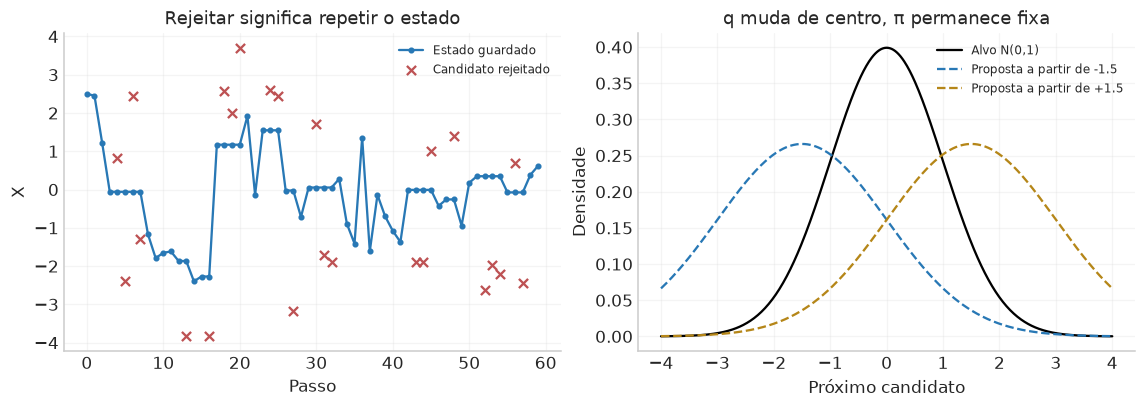

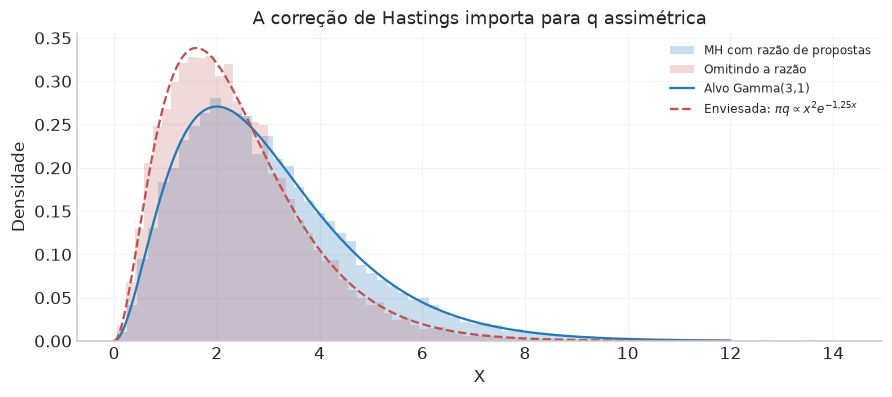

In [9]:
# Uma curta execução mostra candidatos, aceitação e repetições.
lognormal=lambda a:-.5*a[0]**2
mini=metropolis(lognormal,[2.5],60,escala=1.5,seed=1401,guardar_propostas=True)
fig,ax=plt.subplots(1,2,figsize=(10.3,3.6),constrained_layout=True)
t=np.arange(60);ax[0].plot(t,mini['chain'][:,0],'-o',ms=3,color=AZUL,label='Estado guardado')
rej=~mini['accepted'];rej[0]=False
ax[0].scatter(t[rej],mini['proposals'][rej,0],marker='x',color=VERMELHO,label='Candidato rejeitado')
ax[0].set(xlabel='Passo',ylabel='X',title='Rejeitar significa repetir o estado');ax[0].legend(fontsize=8)
xx=np.linspace(-4,4,500);ax[1].plot(xx,stats.norm.pdf(xx),color='black',label='Alvo N(0,1)')
for origem,cor in [(-1.5,AZUL),(1.5,OURO)]:ax[1].plot(xx,stats.norm.pdf(xx,origem,1.5),'--',color=cor,label=f'Proposta a partir de {origem:+.1f}')
ax[1].set(xlabel='Próximo candidato',ylabel='Densidade',title='q muda de centro, π permanece fixa');ax[1].legend(fontsize=8)
figura(fig,'09_propostas_aceitacao')
# Exemplo assimétrico: proposta independente exponencial; alvo Gamma(3, escala 1).
def loggamma(a):
    v=a[0];return 2*np.log(v)-v if v>0 else -np.inf
q_ind=lambda atual,rng:np.array([rng.exponential(4.)])
logq_ind=lambda novo,atual:-np.log(4)-novo[0]/4 if novo[0]>=0 else -np.inf
correto=metropolis(loggamma,[2.],26000,seed=1402,proposta=q_ind,logq=logq_ind)
sem_razao=metropolis(loggamma,[2.],26000,seed=1403,proposta=q_ind)
fig,ax=plt.subplots(figsize=(8,3.5),constrained_layout=True)
xx=np.linspace(0,12,500)
ax.hist(correto['chain'][1000:,0],bins=70,density=True,color=AZUL,alpha=.25,label='MH com razão de propostas')
ax.hist(sem_razao['chain'][1000:,0],bins=70,density=True,color=VERMELHO,alpha=.22,label='Omitindo a razão')
ax.plot(xx,stats.gamma.pdf(xx,3),color=AZUL,label='Alvo Gamma(3,1)')
ax.plot(xx,stats.gamma.pdf(xx,3,scale=1/1.25),'--',color=VERMELHO,label=r'Enviesada: $\pi q\propto x^2 e^{-1{,}25x}$')
ax.set(xlabel='X',ylabel='Densidade',title='A correção de Hastings importa para q assimétrica');ax.legend(fontsize=8)
figura(fig,'10_hastings_assimetrico')

Na proposta independente, $q(y\mid x)=q(y)$. Se omitirmos sua razão reversa, o fluxo satisfaz balanço para uma densidade proporcional a $\pi(x)q(x)$, pois
$\pi(x)q(x)q(y)\min[1,\pi(y)/\pi(x)]$ é simétrico em $x,y$. No exemplo, isso troca a escala da Gamma. A curva vermelha permite identificar qual erro estamos produzindo, além de perceber visualmente que as amostras diferem.

## 5. Exemplo 1 dos slides: posterior de Poisson

A distribuição alvo está dada sobre um **estado inteiro** $X\in\{0,1,2,\ldots\}$:
$$
\pi(x)=\frac{\lambda^xe^{-\lambda}}{x!},\qquad\lambda=3.
$$
Aqui $\lambda$ está fixo; estamos amostrando o estado $X$ da distribuição especificada. Um problema de inferência de uma taxa $\lambda$ a partir de contagens teria outra posterior, construída a partir de likelihood e prior para essa taxa.

A proposta dos slides é $Y=X_t+1$ ou $X_t-1$, cada uma com probabilidade $1/2$. No interior do suporte, a proposta é simétrica. A razão simplifica para
$$
\frac{\pi(x+1)}{\pi(x)}=\frac{\lambda}{x+1},
\qquad\frac{\pi(x-1)}{\pi(x)}=\frac{x}{\lambda}\quad(x\geq1).
$$
No estado zero, uma proposta $Y=-1$ tem probabilidade alvo zero e é rejeitada. Essa permanência faz parte do kernel. Vamos usar **1000 estados guardados**, começando em $X_0=10$, e retirar os primeiros 100 para a comparação de frequências, como nos slides.

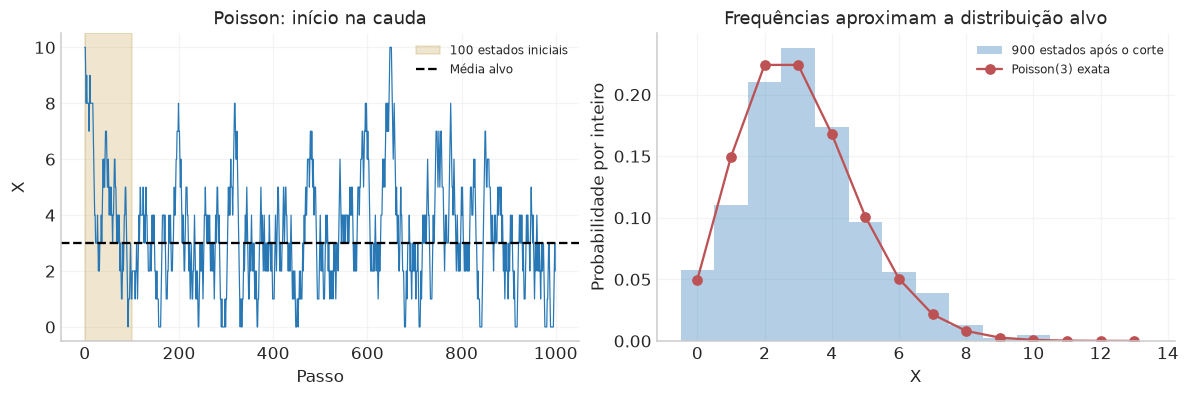

Média após o corte = 3.197; variância = 3.448; valores alvo = 3 e 3.


In [10]:
def logpoisson(a):
    v=a[0]
    return v*np.log(3)-3-special.gammaln(v+1) if v>=0 and v==np.floor(v) else -np.inf
propor_vizinho=lambda atual,rng:atual+rng.choice([-1.,1.])
pois=metropolis(logpoisson,[10.],1000,seed=1501,proposta=propor_vizinho)
cp=pois['chain'][:,0].astype(int);gradep=np.arange(14)
fig,ax=plt.subplots(1,2,figsize=(10.7,3.5),constrained_layout=True)
ax[0].plot(cp,color=AZUL,lw=.8);ax[0].axvspan(0,100,color=OURO,alpha=.2,label='100 estados iniciais')
ax[0].axhline(3,color='black',ls='--',label='Média alvo');ax[0].set(xlabel='Passo',ylabel='X',title='Poisson: início na cauda');ax[0].legend(fontsize=8)
ax[1].hist(cp[100:],bins=np.arange(-.5,14.5),density=True,color=AZUL,alpha=.35,label='900 estados após o corte')
ax[1].plot(gradep,stats.poisson.pmf(gradep,3),'o-',color=VERMELHO,label='Poisson(3) exata')
ax[1].set(xlabel='X',ylabel='Probabilidade por inteiro',title='Frequências aproximam a distribuição alvo');ax[1].legend(fontsize=8)
figura(fig,'11_poisson_slides')
print(f'Média após o corte = {cp[100:].mean():.3f}; variância = {cp[100:].var(ddof=1):.3f}; valores alvo = 3 e 3.')
# Mais passos conferem o algoritmo; a execução curta foi mantida na figura dos slides.
pois_long=metropolis(logpoisson,[10.],50000,seed=1502,proposta=propor_vizinho)
verificar('Suporte inteiro não negativo na Poisson',np.all(pois_long['chain']>=0))
verificar('Média da Poisson em execução longa',abs(pois_long['chain'][2000:,0].mean()-3)<.2)

## 6. Exemplo 2 dos slides: mistura de duas gaussianas

A posterior é
$$
\pi(\boldsymbol x)=\tfrac12\mathcal N_2(\boldsymbol x;\mu_1,C_1)
+\tfrac12\mathcal N_2(\boldsymbol x;\mu_2,C_2),
$$
com
$$
\mu_1=(0,0),\quad C_1=I,
\qquad\mu_2=(4,0),\quad
C_2=\begin{pmatrix}2&0{,}8\\0{,}8&2\end{pmatrix}.
$$
O fator $1/2$ dá a cada componente metade da massa total. A altura de seus máximos difere porque suas covariâncias diferem. **Massa de um componente e altura do pico são quantidades distintas.**

Usaremos $q(y\mid x)=\mathcal N_2(y;x,\operatorname{diag}(\sigma_1^2,\sigma_2^2))$, com $\sigma_1=\sigma_2=1$, 8000 estados e descarte ilustrativo dos primeiros 50. As marginais exatas são somas das marginais gaussianas. A média conjunta é $(2,0)$ e, pela lei da covariância total,
$$
C=\tfrac12C_1+\tfrac12C_2
+\tfrac12(\mu_1-\mu)(\mu_1-\mu)^T
+\tfrac12(\mu_2-\mu)(\mu_2-\mu)^T
=\begin{pmatrix}5{,}5&0{,}4\\0{,}4&1{,}5\end{pmatrix}.
$$
Esses valores são referências úteis para verificar a amostragem; a covariância sozinha ainda deixa escondida a bimodalidade.

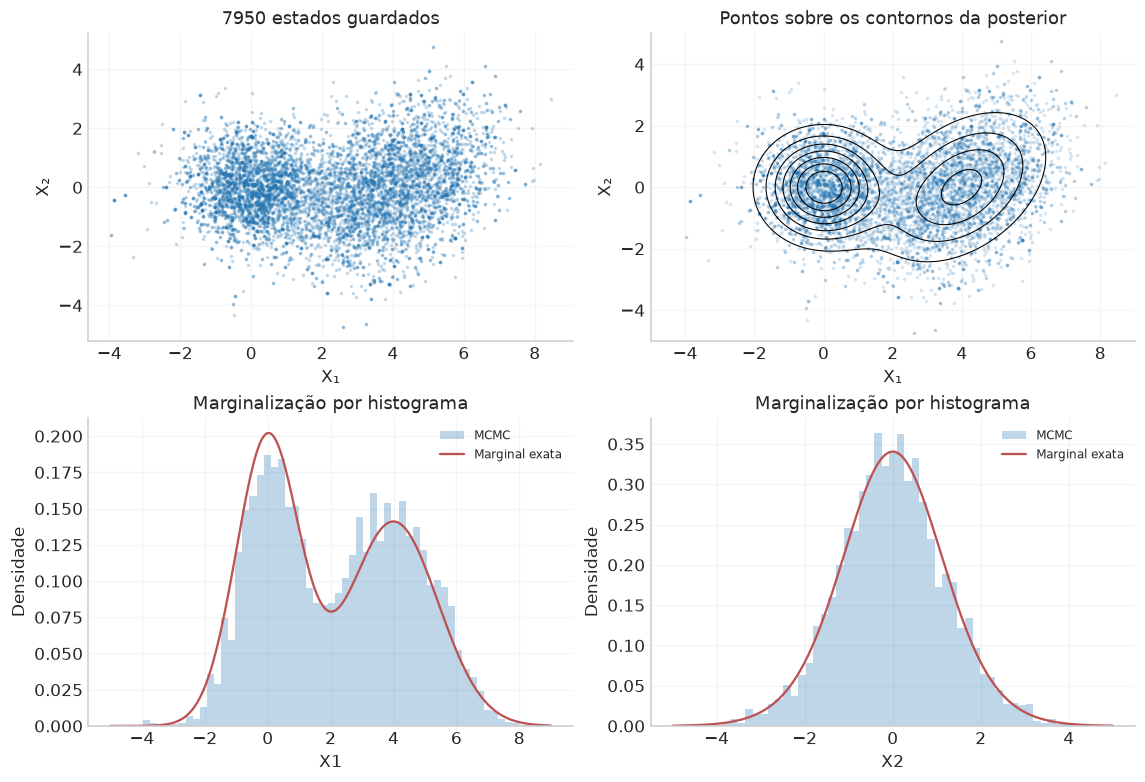

,Parâmetro,Média MCMC,Média exata,Variância MCMC,Variância exata
0,X₁,2.22785,2.0,5.28933,5.5
1,X₂,0.00392,0.0,1.48167,1.5


In [11]:
mu1=np.array([0.,0.]);mu2=np.array([4.,0.]);C1=np.eye(2);C2=np.array([[2.,.8],[.8,2.]])
inv2=np.linalg.inv(C2);ld2=np.linalg.slogdet(C2)[1]
def logmix(a):
    v=np.asarray(a);r=v-mu2
    l1=-np.log(2*np.pi)-.5*np.sum(v*v,axis=-1)
    l2=-np.log(2*np.pi)-.5*ld2-.5*np.einsum('...i,ij,...j->...',r,inv2,r)
    return np.logaddexp(l1,l2)-np.log(2)
def marginal_mix(xx,j):
    return .5*stats.norm.pdf(xx,mu1[j],np.sqrt(C1[j,j]))+.5*stats.norm.pdf(xx,mu2[j],np.sqrt(C2[j,j]))
sl_mix=metropolis(logmix,[-4.5,4.5],8000,escala=1.,seed=1601)
cm=sl_mix['chain'][50:]
gx=np.linspace(-5,9,240);gy=np.linspace(-5,5,210);MX,MY=np.meshgrid(gx,gy)
PM=np.exp(logmix(np.stack([MX,MY],axis=-1)))
fig,ax=plt.subplots(2,2,figsize=(10.3,7),constrained_layout=True)
ax[0,0].scatter(cm[:,0],cm[:,1],s=2,alpha=.2,color=AZUL);ax[0,0].set(xlabel='X₁',ylabel='X₂',title='7950 estados guardados')
ax[0,1].contour(MX,MY,PM,levels=7,colors='black',linewidths=.7)
ax[0,1].scatter(cm[:,0],cm[:,1],s=2,alpha=.13,color=AZUL);ax[0,1].set(xlabel='X₁',ylabel='X₂',title='Pontos sobre os contornos da posterior')
for j in [0,1]:
    ax[1,j].hist(cm[:,j],bins=55,density=True,color=AZUL,alpha=.3,label='MCMC')
    vv=np.linspace(-5,9 if j==0 else 5,500)
    ax[1,j].plot(vv,marginal_mix(vv,j),color=VERMELHO,label='Marginal exata')
    ax[1,j].set(xlabel=f'X{j+1}',ylabel='Densidade',title='Marginalização por histograma');ax[1,j].legend(fontsize=8)
figura(fig,'12_mistura_slides')
tabela(pd.DataFrame({'Parâmetro':['X₁','X₂'],'Média MCMC':cm.mean(axis=0),'Média exata':[2.,0.],
    'Variância MCMC':cm.var(axis=0,ddof=1),'Variância exata':[5.5,1.5]}),'mistura_resultados')

## 7. Burn-in: a memória da inicialização

A condição inicial define uma distribuição $\mu_0$; a cada etapa aplicamos o kernel: $\mu_t=\mu_0K^t$. O burn-in corresponde à fase em que essa distribuição ainda difere de maneira relevante da estacionária para o objetivo da análise.

Um exemplo em que podemos abrir as contas é a cadeia autorregressiva
$$
X_{t+1}=\phi X_t+\sqrt{1-\phi^2}\,\epsilon_t,
\qquad\epsilon_t\overset{\rm iid}{\sim}\mathcal N(0,1),\quad |\phi|<1.
$$
Se $X_t\sim\mathcal N(0,1)$, o próximo estado também tem média zero e variância $\phi^2+(1-\phi^2)=1$: a normal padrão é estacionária. Partindo de um valor fixo $X_0=x_0$,
$$
X_t=\phi^t x_0+\sqrt{1-\phi^2}\sum_{j=0}^{t-1}\phi^j\epsilon_{t-1-j}.
$$
Logo,
$$
\mathbb E[X_t\mid x_0]=\phi^t x_0,
\quad\operatorname{Var}(X_t\mid x_0)=1-\phi^{2t}.
$$
A média relaxa até zero e a variância se aproxima de 1. Para $0<\phi<1$, $\phi^t=e^{-t/\tau_{\exp}}$, com
$\tau_{\exp}=-1/\log\phi$. Após várias escalas de relaxação, a influência inicial fica menor; a duração necessária também depende de quão distante está $x_0$ e da precisão exigida.

**$\tau_{\exp}$ caracteriza a dinâmica.** Podemos reduzi-lo ao melhorar a proposta; escolher um número menor na análise altera apenas nossa descrição. Um corte de burn-in remove parte do viés inicial, enquanto autocorrelações ainda permanecem na fase estacionária. Uma cadeia pode atingir um modo rapidamente e demorar muito mais para explorar outros.

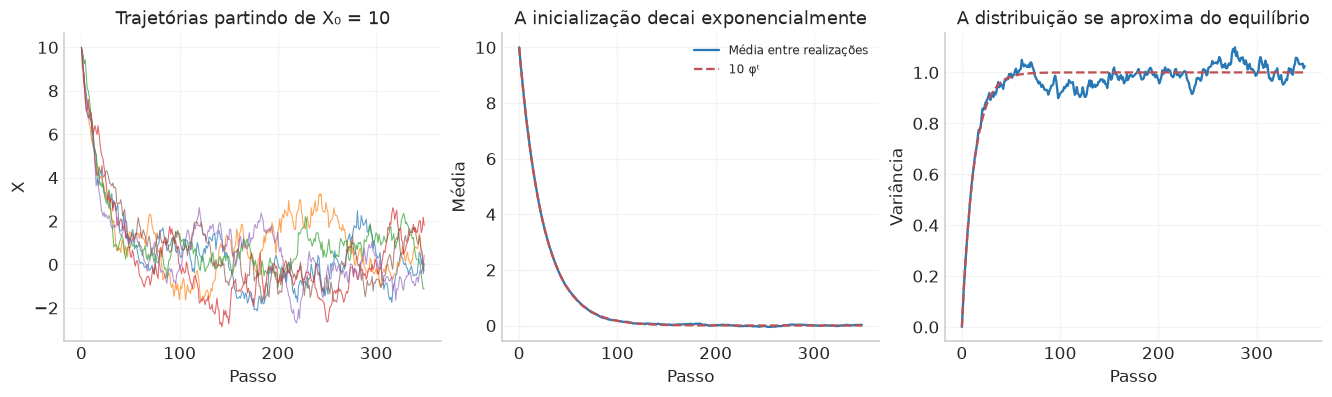

φ = 0.96; τ_exp = 24.50 passos. Cinco τ_exp ≈ 122 passos neste exemplo.


In [12]:
phi=.96;texp=-1/np.log(phi);ar_steps=350;ar_rep=1600
rng_ar=np.random.default_rng(1701);ar=np.empty((ar_rep,ar_steps));ar[:,0]=10.
for t in range(1,ar_steps):ar[:,t]=phi*ar[:,t-1]+np.sqrt(1-phi**2)*rng_ar.normal(size=ar_rep)
t=np.arange(ar_steps)
fig,ax=plt.subplots(1,3,figsize=(12,3.5),constrained_layout=True)
ax[0].plot(ar[:6].T,lw=.7,alpha=.7);ax[0].set(xlabel='Passo',ylabel='X',title='Trajetórias partindo de X₀ = 10')
ax[1].plot(t,ar.mean(axis=0),color=AZUL,label='Média entre realizações');ax[1].plot(t,10*phi**t,'--',color=VERMELHO,label='10 φᵗ')
ax[1].set(xlabel='Passo',ylabel='Média',title='A inicialização decai exponencialmente');ax[1].legend(fontsize=8)
ax[2].plot(t,ar.var(axis=0),color=AZUL);ax[2].plot(t,1-phi**(2*t),'--',color=VERMELHO)
ax[2].set(xlabel='Passo',ylabel='Variância',title='A distribuição se aproxima do equilíbrio')
figura(fig,'13_burnin_relaxacao')
print(f'φ = {phi}; τ_exp = {texp:.2f} passos. Cinco τ_exp ≈ {5*texp:.0f} passos neste exemplo.')

## 8. Escala da proposta: três experimentos com o mesmo alvo

Retomamos a mistura dos slides, sempre com início $(-4{,}5,4{,}5)$, e variamos $\sigma_q=0{,}1,1,10$. Esse $\sigma_q$ pertence à **distribuição de proposta**, enquanto as covariâncias $C_1,C_2$ pertencem à posterior e permanecem fixas.

- **Passo pequeno:** candidatos próximos costumam ser aceitos; muitas etapas são necessárias para percorrer a largura de um modo ou chegar a outro.
- **Passo intermediário:** pode equilibrar deslocamento e aceitação para a geometria deste problema.
- **Passo grande:** muitos candidatos caem em regiões de baixa densidade e são rejeitados; o estado se repete por várias etapas.

A taxa de aceitação mede uma parte desse comportamento. Para comparar eficiência, precisamos também do tamanho dos deslocamentos, da autocorrelação e do custo por avaliação. Aumentar indefinidamente a proposta pode aumentar a autocorrelação devido às permanências; a relação é dependente do problema.

Guardaremos 40000 estados por caso para os diagnósticos e desenharemos os primeiros 8000 para tornar visível a fase inicial. Os cortes e comprimentos são escolhas didáticas, que serão avaliadas pelos próprios gráficos.

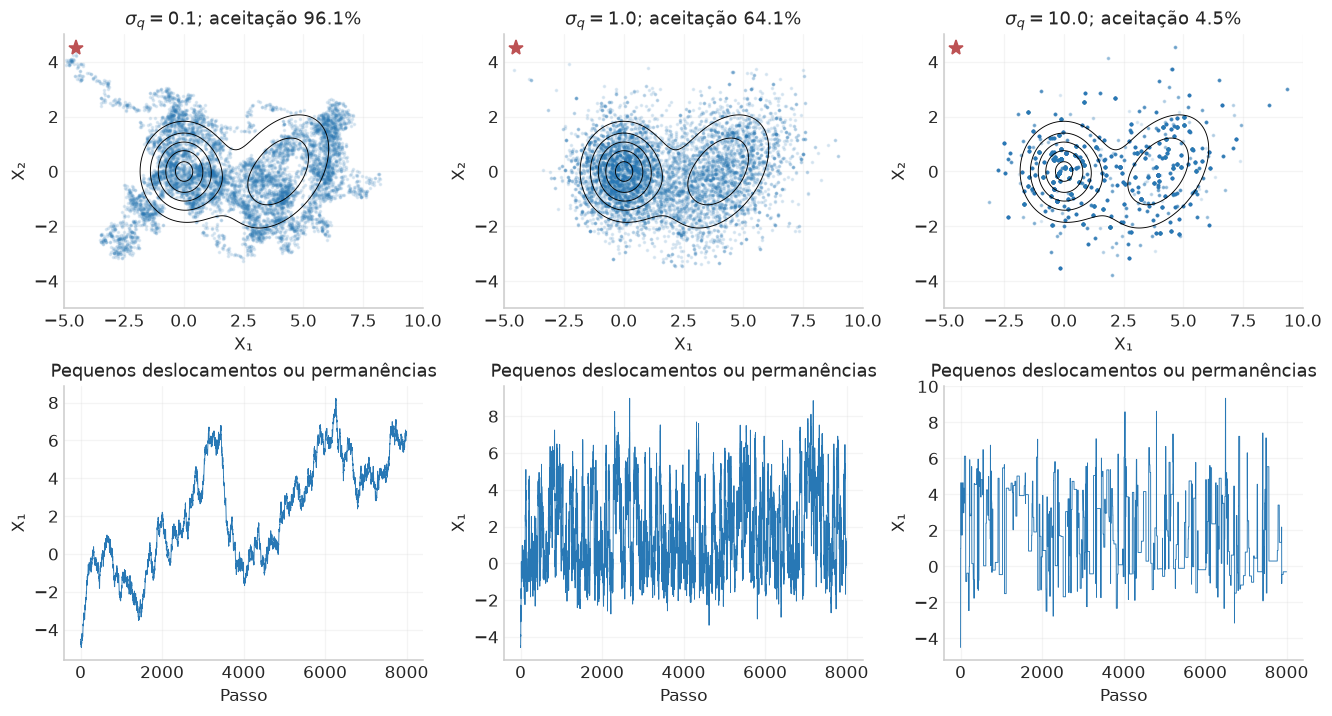

,σ proposta,Aceitação,τ int X₁,τ int X₂,ESS X₁,ESS X₂,Média X₁
0,0.1,0.961,1848.029,510.192,19.480,70.562,2.049
1,1.0,0.641,45.375,12.304,793.386,2925.912,1.872
2,10.0,0.045,43.150,30.552,834.299,1178.305,1.889


In [13]:
propostas={s:metropolis(logmix,[-4.5,4.5],40000,escala=s,seed=1800+i) for i,s in enumerate([.1,1.,10.])}
fig,ax=plt.subplots(2,3,figsize=(12,6.4),constrained_layout=True)
res_prop=[]
for j,(s,res) in enumerate(propostas.items()):
    c=res['chain'];ax[0,j].contour(MX,MY,PM,levels=6,colors='black',linewidths=.6)
    ax[0,j].scatter(c[:8000,0],c[:8000,1],s=2,alpha=.12,color=AZUL)
    ax[0,j].plot(*c[0],marker='*',color=VERMELHO,ms=10)
    ax[0,j].set(xlabel='X₁',ylabel='X₂',xlim=(-5,10),ylim=(-5,5),title=fr'$\sigma_q={s}$; aceitação {res["acceptance"]:.1%}')
    ax[1,j].plot(c[:8000,0],color=AZUL,lw=.6);ax[1,j].set(xlabel='Passo',ylabel='X₁',title='Pequenos deslocamentos ou permanências')
    cpos=c[4000:];t1,_=tau_integrado(cpos[:,0]);t2,_=tau_integrado(cpos[:,1])
    res_prop.append({'σ proposta':s,'Aceitação':res['acceptance'],'τ int X₁':t1,'τ int X₂':t2,
        'ESS X₁':len(cpos)/t1,'ESS X₂':len(cpos)/t2,'Média X₁':cpos[:,0].mean()})
figura(fig,'14_propostas_sigmas_slides')
tabela(pd.DataFrame(res_prop),'escalas_proposta',casas=3)

### 8.1 Por que precisamos guardar as repetições?

Se a chance de sair do estado $x$ é $a(x)=1-r(x)$, a cadeia que registra somente as mudanças tem kernel $J(x,dy)=K(x,dy)/a(x)$ fora da diagonal. Seu fluxo é reversível para uma densidade proporcional a $\pi(x)a(x)$, em vez de representar diretamente $\pi(x)$. Estados com saída fácil ficam super-representados nessa lista de saltos.

As repetições guardam o tempo de ocupação necessário à distribuição alvo. Podemos comprimi-las em um único estado com peso inteiro, como faz o Cobaya, e usar esses pesos nas estatísticas. Para uma ACF em unidades de passos, devemos reconstruir a ordem e as permanências; analisar somente linhas de pontos aceitos muda a escala temporal e a distribuição da sequência.

### 8.2 Uma proposta que acompanha a covariância

Em uma gaussiana alongada, uma proposta isotrópica precisa respeitar a direção estreita para manter aceitação razoável. Podemos propor
$Y=X+sL_qz$. Vamos definir cada objeto: $X$ é o estado atual, $Y$ é o candidato, $s>0$ ajusta o tamanho global do passo e $z$ contém gaussianas independentes de média zero e variância um, isto é, $z\sim\mathcal N(0,I)$. Escolhemos uma matriz de covariância positiva definida $C_q$. Seu fator de Cholesky $L_q$ é uma matriz triangular inferior que satisfaz $L_qL_q^T=C_q$.

O vetor $z$ fornece um deslocamento sem direção preferida; multiplicá-lo por $L_q$ alonga e gira esse deslocamento. Explicitamente,
$$
\mathbb E[Y-X]=sL_q\mathbb E[z]=0,
\qquad \operatorname{Cov}(Y-X)=s^2L_q\mathbb E[zz^T]L_q^T
=s^2L_qIL_q^T=s^2C_q.
$$
Assim, $q(Y\mid X)=\mathcal N(Y;X,s^2C_q)$. Ela continua simétrica se a covariância é fixa: trocar $X$ por $Y$ apenas muda o sinal do deslocamento dentro da mesma forma quadrática. Escolher $C_q$ próxima à covariância da posterior permite passos maiores na direção larga e menores na estreita. É a construção matricial do capítulo 10 aplicada **às propostas**; a covariância dos erros observacionais continua sendo outro objeto.

Na função `metropolis`, `escala` escalar significa desvio padrão comum, um vetor significa desvios por coordenada e uma matriz significa a covariância completa da proposta. Para a matriz usada abaixo, o código calcula seu Cholesky e o armazena na variável `L`; o comando `L @ rng.normal(size=dim)` implementa precisamente essa transformação. O fator $2{,}38/\sqrt{2}$ é uma escolha de escala neste exemplo, cujo desempenho vamos medir.

A adaptação da proposta usa informação acumulada e exige condições próprias de validade, como adaptação decrescente e controle da exploração. No código manual deste notebook a proposta fica fixa durante cada execução; aprender uma proposta no aquecimento e congelá-la na etapa de produção separa bem os dois objetivos.

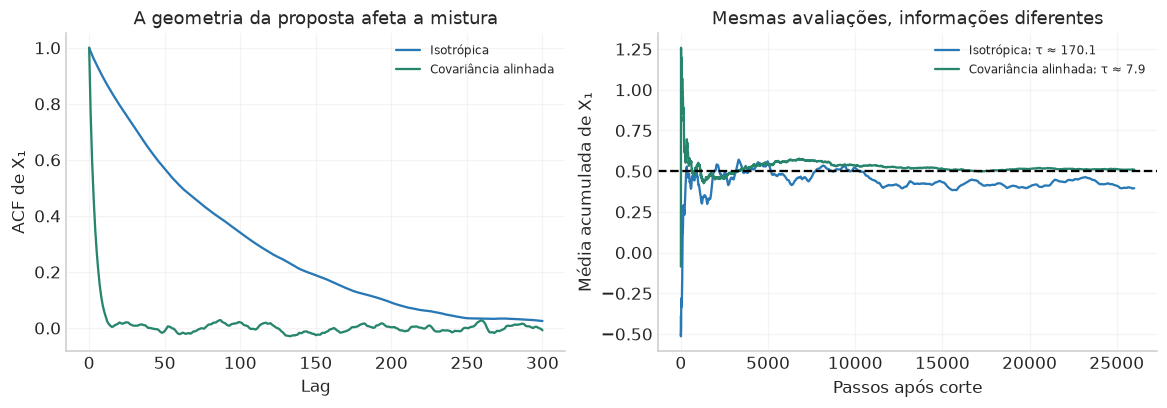

In [14]:
mu_corr=np.array([.5,-1.]);C_corr=np.array([[1.,.98],[.98,1.]]);W_corr=np.linalg.inv(C_corr)
def log_corr(v):
    r=v-mu_corr;return -.5*r@W_corr@r
isotrop=metropolis(log_corr,[3.,3.],28000,escala=.35,seed=1804)
precond=metropolis(log_corr,[3.,3.],28000,escala=(2.38**2/2)*C_corr,seed=1805)
fig,ax=plt.subplots(1,2,figsize=(10.5,3.6),constrained_layout=True)
for res,cor,lab in [(isotrop,AZUL,'Isotrópica'),(precond,VERDE,'Covariância alinhada')]:
    c=res['chain'][2000:];rho=acf_fft(c[:,0],300)
    ax[0].plot(rho,color=cor,label=lab)
    tau,_=tau_integrado(c[:,0]);ax[1].plot(np.cumsum(c[:,0])/np.arange(1,len(c)+1),color=cor,label=f'{lab}: τ ≈ {tau:.1f}')
ax[0].set(xlabel='Lag',ylabel='ACF de X₁',title='A geometria da proposta afeta a mistura');ax[0].legend(fontsize=8)
ax[1].axhline(mu_corr[0],color='black',ls='--');ax[1].set(xlabel='Passos após corte',ylabel='Média acumulada de X₁',title='Mesmas avaliações, informações diferentes');ax[1].legend(fontsize=8)
figura(fig,'15_proposta_covariancia')

## 9. O que significa $\rho(h)$ e de onde vem sua fórmula?

Ele representa uma **correlação**, e $h$ é a distância entre dois índices da cadeia, chamada *lag*.

Fixemos uma quantidade $F_t=f(X_t)$, como $X_{t,1}$, $X_{t,2}$ ou $X_{t,1}^2$. Em uma cadeia estacionária, a média $\mu_f$ e a variância $\sigma_f^2$ são constantes. A autocovariância e a autocorrelação são
$$
\gamma_f(h)=\mathbb E[(F_t-\mu_f)(F_{t+h}-\mu_f)],
\qquad\rho_f(h)=\frac{\gamma_f(h)}{\gamma_f(0)}.
$$
É o coeficiente de Pearson aplicado à série e a uma cópia deslocada dela. Em uma sequência finita, usamos os pares que se sobrepõem. Se $a_t=F_t-\bar F$ e $b_t=F_{t+h}-\bar F$, o estimador apresentado nos slides é
$$
\widehat\rho(h)=\frac{\sum_{t=1}^{n-h}a_tb_t}
{\sqrt{\sum_{t=1}^{n-h}a_t^2}\sqrt{\sum_{t=1}^{n-h}b_t^2}}.
$$
A normalização torna a correlação adimensional e limitada em módulo por 1, pela desigualdade de Cauchy–Schwarz. Outras convenções estimam primeiro a autocovariância e dividem pelo valor no lag zero; os fatores de borda diferem em amostras finitas. No limite de uma série longa e em lags pequenos, estimam o mesmo objeto populacional. Nossa função FFT usa a normalização por lag zero e será comparada à fórmula de sobreposição.

**Interpretação:** $\rho(h)>0$ significa que flutuações de mesmo sinal em relação à média tendem a permanecer após $h$ etapas. Valores negativos indicam tendência de alternância. $\rho(0)=1$ porque comparamos cada valor consigo mesmo. Correlação próxima de zero sinaliza pouca associação linear naquele lag; independência é uma propriedade mais forte.

Na cadeia AR(1), podemos derivar exatamente:
$$
X_{t+h}=\phi^hX_t+\text{ruído futuro independente de }X_t.
$$
Em equilíbrio, $\gamma(h)=\phi^h\operatorname{Var}(X_t)=\phi^h$ e
$$
\rho(h)=\phi^h=e^{-h/\tau_{\exp}},\qquad \tau_{\exp}=-1/\log\phi\quad(0<\phi<1).
$$
Para kernels reversíveis, diferentes modos de relaxação podem contribuir para a ACF como uma combinação de decaimentos. Um único exponencial é uma descrição simples de um comportamento que pode ter várias escalas. A escala mais lenta pode aparecer na troca de modos e ficar quase invisível em uma coordenada específica.

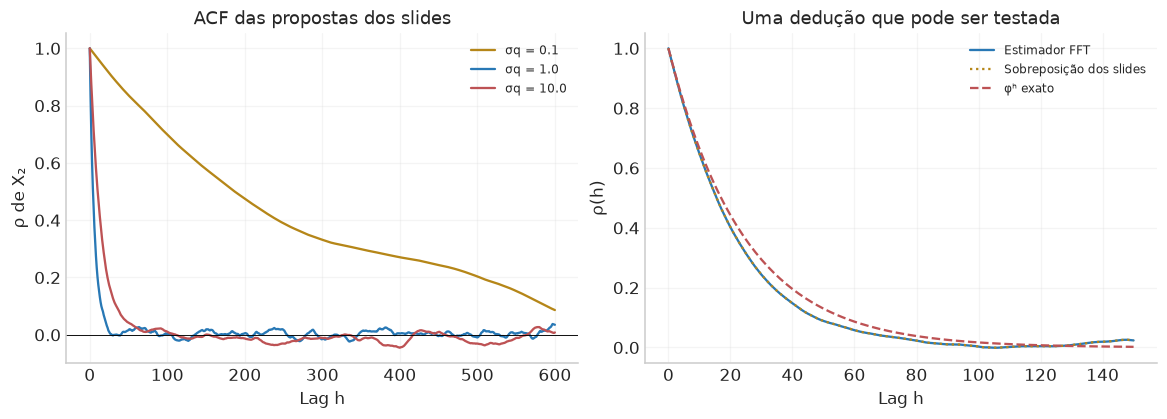

In [15]:
def acf_overlap(a,maxlag):
    v=np.asarray(a)-np.mean(a);result=[]
    for h in range(maxlag+1):
        aa=v[:len(v)-h];bb=v[h:]
        result.append(aa@bb/np.sqrt((aa@aa)*(bb@bb)))
    return np.array(result)
fig,ax=plt.subplots(1,2,figsize=(10.5,3.7),constrained_layout=True)
for (s,res),cor in zip(propostas.items(),[OURO,AZUL,VERMELHO]):
    rho=acf_fft(res['chain'][4000:,1],600);ax[0].plot(rho,color=cor,label=f'σq = {s}')
ax[0].axhline(0,color='black',lw=.6);ax[0].set(xlabel='Lag h',ylabel='ρ de X₂',title='ACF das propostas dos slides');ax[0].legend(fontsize=8)
# Uma AR(1) estacionária longa permite confrontar a fórmula exata.
rng_ar2=np.random.default_rng(1901);ar_stat=np.empty(60000);ar_stat[0]=rng_ar2.normal()
for t in range(1,len(ar_stat)):ar_stat[t]=phi*ar_stat[t-1]+np.sqrt(1-phi**2)*rng_ar2.normal()
h=np.arange(151)
ax[1].plot(h,acf_fft(ar_stat,150),color=AZUL,label='Estimador FFT')
ax[1].plot(h,acf_overlap(ar_stat,150),':',color=OURO,label='Sobreposição dos slides')
ax[1].plot(h,phi**h,'--',color=VERMELHO,label='φʰ exato')
ax[1].set(xlabel='Lag h',ylabel='ρ(h)',title='Uma dedução que pode ser testada');ax[1].legend(fontsize=8)
figura(fig,'16_autocorrelacao_rho')

### 9.1 Autocorrelação integrada e erro Monte Carlo

Se estimamos uma esperança por $\bar F_n=n^{-1}\sum_{t=1}^nF_t$, sua variância envolve todos os pares:
$$
\begin{aligned}
\operatorname{Var}(\bar F_n)
&=\frac1{n^2}\sum_{t,s=1}^n\operatorname{Cov}(F_t,F_s)\\
&=\frac1{n^2}\left[n\gamma(0)+2\sum_{h=1}^{n-1}(n-h)\gamma(h)\right]\\
&=\frac{\sigma_f^2}{n}\underbrace{\left[1+2\sum_{h=1}^{n-1}\left(1-\frac hn\right)\rho_f(h)\right]}_{\tau_{f,n}}.
\end{aligned}
$$
Quando a soma das autocorrelações converge e a cadeia é longa,
$$
\tau_{\rm int,f}=1+2\sum_{h=1}^{\infty}\rho_f(h),
\quad N_{\rm eff,f}\simeq n/\tau_{\rm int,f},
\quad\operatorname{MCSE}(\bar F)\simeq\sqrt{\widehat\sigma_f^2\tau_{\rm int,f}/n}.
$$
O MCSE mede incerteza **numérica** da média posterior estimada. O desvio da posterior descreve incerteza **estatística** sobre o parâmetro. Aumentar a cadeia reduz o primeiro; a distribuição alvo permanece a mesma.

Para a AR(1), a soma geométrica dá
$$
\tau_{\rm int}=1+\frac{2\phi}{1-\phi}=\frac{1+\phi}{1-\phi}.
$$
Com $\phi=0{,}96$, temos $\tau_{\exp}\simeq24{,}5$ e $\tau_{\rm int}=49$. São números relacionados, com definições distintas. O primeiro caracteriza um decaimento; o segundo soma o efeito da dependência sobre a variância de uma média.

Em dados finitos, somar a ACF até lags enormes acumula ruído. A função `tau_integrado` usa uma janela baseada em pares iniciais positivos, apropriada como estimador didático para os exemplos reversíveis com autocorrelações positivas dominantes. O resultado também pode ser instável se a execução for curta. ESS deve ser calculado para quantidades relevantes, inclusive indicadores de modos, e avaliado junto à exploração global. O corte em 1 implementado no estimador é conservador para estes exemplos; processos anticorrelacionados podem ter $\tau_{\rm int}<1$.

In [16]:
tau_ar_estimado,j_ar=tau_integrado(ar_stat);tau_ar_exato=(1+phi)/(1-phi)
print(f'AR(1): τ_int exato = {tau_ar_exato:.2f}; estimado = {tau_ar_estimado:.2f}; janela = {j_ar}.')
verificar('Autocorrelação integrada da AR(1)',abs(tau_ar_estimado/tau_ar_exato-1)<.3)
regs=[]
for s,res in propostas.items():
    c=res['chain'][4000:]
    for lab,v in [('X₁',c[:,0]),('X₂',c[:,1]),('Indicador X₁ > 2', (c[:,0]>2).astype(float))]:
        ti,jan=tau_integrado(v)
        regs.append({'σ proposta':s,'Quantidade':lab,'τ integrado':ti,'ESS':len(v)/ti,
            'MCSE da média':np.sqrt(v.var(ddof=1)*ti/len(v)),'Janela':jan})
tabela(pd.DataFrame(regs),'ess_quantidades',casas=3)

AR(1): τ_int exato = 49.00; estimado = 42.55; janela = 102.


,σ proposta,Quantidade,τ integrado,ESS,MCSE da média,Janela
0,0.1,X₁,1848.029,19.480,0.481,2736
1,0.1,X₂,510.192,70.562,0.140,714
2,0.1,Indicador X₁ > 2,1762.169,20.429,0.111,3096
3,1.0,X₁,45.375,793.386,0.084,188
4,1.0,X₂,12.304,2925.912,0.022,28
5,1.0,Indicador X₁ > 2,37.684,955.306,0.016,80
6,10.0,X₁,43.150,834.299,0.081,84
7,10.0,X₂,30.552,1178.305,0.036,110
8,10.0,Indicador X₁ > 2,54.773,657.259,0.019,290


## 10. Gelman–Rubin: comparar a exploração dentro e entre cadeias

Usaremos primeiro **a fórmula escalar dos slides**, mantendo seus símbolos. Para um parâmetro, executamos $M$ cadeias independentes, com $n$ estados retidos em cada uma. Definimos
$$
\bar\theta_m=\frac1n\sum_{t=1}^n\theta_{mt},
\quad S_m^2=\frac1{n-1}\sum_t(\theta_{mt}-\bar\theta_m)^2,
\quad\bar\theta=\frac1M\sum_m\bar\theta_m.
$$
As duas escalas são
$$
s^2=\frac1M\sum_m S_m^2,
\qquad\Sigma^2=\frac1{M-1}\sum_m(\bar\theta_m-\bar\theta)^2.
$$
$s^2$ mede a dispersão média **dentro** das cadeias. $\Sigma^2$ mede a dispersão **das médias** das cadeias e tem a escala da incerteza de uma média. Na notação frequente, $W=s^2$ e $B=n\Sigma^2$.

A combinação dos slides é
$$
\boxed{\widehat V=\frac{n-1}{n}s^2+\Sigma^2,
\qquad \widehat R^2=\widehat V/s^2.}
$$
Se cada cadeia cobre apenas uma região estreita, $s^2$ pode ser pequeno. Médias de cadeias iniciadas em regiões diferentes podem discordar e aumentar $\Sigma^2$. Quando cadeias longas exploram a mesma posterior, $s^2$ se aproxima da variância alvo, $\Sigma^2$ diminui e $\widehat R$ se aproxima de 1.

### 10.1 Por que $\widehat V$ é não enviesado sob estacionariedade?

Vamos demonstrar, explicitando as hipóteses. Cada cadeia já é **estacionária na mesma distribuição**, com média $\mu$ e variância finita $\sigma_\pi^2$, e as cadeias são independentes entre si. Dentro de cada cadeia pode haver autocorrelação. Seja
$v_n=\operatorname{Var}(\bar\theta_m)$, igual para as cadeias deste argumento.

A identidade algébrica
$$
\sum_t(\theta_{mt}-\bar\theta_m)^2
=\sum_t(\theta_{mt}-\mu)^2-n(\bar\theta_m-\mu)^2
$$
fornece, tomando esperanças,
$$
\mathbb E[S_m^2]
=\frac{n\sigma_\pi^2-nv_n}{n-1},
\qquad\mathbb E[s^2]=\frac n{n-1}(\sigma_\pi^2-v_n).
$$
Agora abrimos a dispersão entre médias:
$$
\sum_m(\bar\theta_m-\bar\theta)^2
=\sum_m(\bar\theta_m-\mu)^2-M(\bar\theta-\mu)^2.
$$
A independência entre cadeias dá $\operatorname{Var}(\bar\theta)=v_n/M$. Portanto,
$$
\mathbb E[\Sigma^2]=\frac{Mv_n-M(v_n/M)}{M-1}=v_n.
$$
Substituímos na combinação:
$$
\boxed{\mathbb E[\widehat V]
=\frac{n-1}{n}\frac n{n-1}(\sigma_\pi^2-v_n)+v_n
=\sigma_\pi^2.}
$$
**O termo entre médias repõe exatamente a contribuição que a centralização por cada média de cadeia retirou da dispersão interna.** É essa identidade que justifica o não viés, sob as hipóteses acima.

Há uma precisão importante na frase dos slides sobre $s^2$. Para amostras IID dentro da cadeia, $v_n=\sigma_\pi^2/n$ e $s^2$ também é não enviesado para qualquer $n$. Em uma MCMC estacionária com autocorrelações positivas, $v_n$ costuma ser maior, e $s^2$ tem viés negativo em tamanho finito. Usando a conta da seção anterior,
$$
v_n=\frac{\sigma_\pi^2}{n}\tau_n,
\quad\mathbb E[s^2]=\sigma_\pi^2\frac{n-\tau_n}{n-1},
\quad\mathbb E[\Sigma^2]=\sigma_\pi^2\frac{\tau_n}{n}.
$$
Sob ergodicidade adequada e com crescimento de $n$, $s^2$ é consistente para $\sigma_\pi^2$. **Estacionariedade das marginais e independência entre etapas são hipóteses diferentes.**

O não viés se refere à média de $\widehat V$ em repetições da simulação. Um valor observado de $\widehat V$ flutua. Além disso, $\mathbb E[\widehat V/s^2]$ envolve uma razão aleatória; a demonstração acima ainda deixa a distribuição de $\widehat R$ por analisar. Antes do equilíbrio, médias iniciais distintas e distribuições transitórias também mudam essas esperanças.

In [17]:
# Repetir conjuntos de AR(1) já estacionárias verifica a esperança do estimador.
rng_v=np.random.default_rng(2001);Rrep,Mrep,nrep=5000,4,80
regs=[]
for ph in [0.,.8,.96]:
    c=np.empty((Rrep,Mrep,nrep));c[:,:,0]=rng_v.normal(size=(Rrep,Mrep))
    for t in range(1,nrep):c[:,:,t]=ph*c[:,:,t-1]+np.sqrt(1-ph*ph)*rng_v.normal(size=(Rrep,Mrep))
    W=c.var(axis=2,ddof=1).mean(axis=1);S=c.mean(axis=2).var(axis=1,ddof=1)
    V=(nrep-1)/nrep*W+S
    h=np.arange(1,nrep);tau_n=1+2*np.sum((1-h/nrep)*ph**h)
    esperado_W=(nrep-tau_n)/(nrep-1);esperado_S=tau_n/nrep
    regs.append({'φ':ph,'E[s²] teórica':esperado_W,'Média simulada s²':W.mean(),
        'E[Σ²] teórica':esperado_S,'Média simulada Σ²':S.mean(),'Média simulada V':V.mean(),
        'Erro MC da média V':V.std(ddof=1)/np.sqrt(Rrep)})
    verificar(f'V não enviesado na AR(1), φ={ph}',abs(V.mean()-1)<5*V.std(ddof=1)/np.sqrt(Rrep))
tabela(pd.DataFrame(regs),'nao_vies_estimadores',casas=5)

,φ,E[s²] teórica,Média simulada s²,E[Σ²] teórica,Média simulada Σ²,Média simulada V,Erro MC da média V
0,0.00,1.00000,1.00000,0.01250,0.01250,1.00000,0.00113
1,0.80,0.90506,0.90006,0.10625,0.10914,0.99796,0.00243
2,0.96,0.57503,0.57155,0.43216,0.43721,1.00161,0.00575


### 10.2 Acompanhar $s^2$, $\Sigma^2$, $\widehat V$ e $\widehat R^2$

Agora executaremos quatro Metropolis independentes com alvo $\mathcal N(0,1)$ e inícios dispersos. Em cada número total de passos $T$, usamos **a metade final de cada prefixo** para o diagnóstico. Essa escolha reduz progressivamente a influência da inicialização e deixa explícita a janela analisada. A variância verdadeira é 1 e serve como referência externa.

Um valor próximo de 1 significa concordância entre essas cadeias para essa estatística. Uma avaliação mais completa também considera o comprimento em unidades de autocorrelação, o MCSE, caudas e a exploração de modos. Na fórmula clássica, $\widehat R$ pode flutuar ligeiramente abaixo de 1.

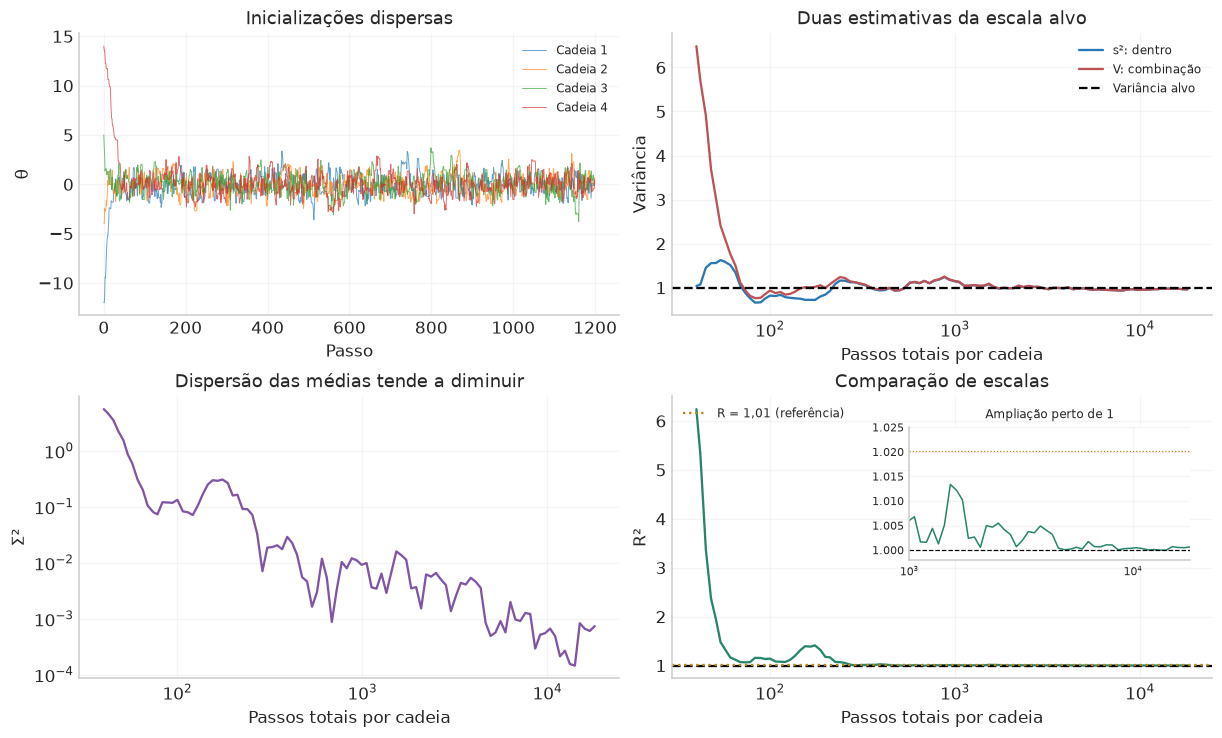

,s2,Sigma2,V,R2,R
0,0.960597,0.000732,0.961223,1.000651,1.000326


Rhat rank-normalizado, split e folded: 1.00049


In [18]:
inicios_gr=[-12.,-4.,5.,14.]
gr_chains=np.array([metropolis(lognormal,[v],18000,escala=1.1,seed=2010+j)['chain'][:,0] for j,v in enumerate(inicios_gr)])
comprimentos=np.unique(np.geomspace(40,18000,100).astype(int))
gr_evol=[gelman_rubin(gr_chains[:,T//2:T]) for T in comprimentos]
fig,ax=plt.subplots(2,2,figsize=(11,6.6),constrained_layout=True)
for j,c in enumerate(gr_chains):ax[0,0].plot(c[:1200],lw=.6,alpha=.7,label=f'Cadeia {j+1}')
ax[0,0].set(xlabel='Passo',ylabel='θ',title='Inicializações dispersas');ax[0,0].legend(fontsize=8)
ax[0,1].plot(comprimentos,[r['s2'] for r in gr_evol],color=AZUL,label='s²: dentro')
ax[0,1].plot(comprimentos,[r['V'] for r in gr_evol],color=VERMELHO,label='V: combinação')
ax[0,1].axhline(1,color='black',ls='--',label='Variância alvo');ax[0,1].set(xscale='log',xlabel='Passos totais por cadeia',ylabel='Variância',title='Duas estimativas da escala alvo');ax[0,1].legend(fontsize=8)
ax[1,0].loglog(comprimentos,[r['Sigma2'] for r in gr_evol],color=ROXO)
ax[1,0].set(xlabel='Passos totais por cadeia',ylabel='Σ²',title='Dispersão das médias tende a diminuir')
ax[1,1].semilogx(comprimentos,[r['R2'] for r in gr_evol],color=VERDE)
ax[1,1].axhline(1,color='black',ls='--');ax[1,1].axhline(1.01**2,color=OURO,ls=':',label='R = 1,01 (referência)')
ax[1,1].set(xlabel='Passos totais por cadeia',ylabel='R²',title='Comparação de escalas');ax[1,1].legend(fontsize=8,loc='upper left')
zoom=ax[1,1].inset_axes([.44,.42,.52,.47])
zoom.semilogx(comprimentos,[r['R2'] for r in gr_evol],color=VERDE,lw=1)
zoom.axhline(1,color='black',ls='--',lw=.8);zoom.axhline(1.01**2,color=OURO,ls=':',lw=.8)
zoom.set(xlim=(1000,18000),ylim=(.998,1.025),title='Ampliação perto de 1')
zoom.title.set_fontsize(8);zoom.tick_params(labelsize=7)
figura(fig,'17_gelman_rubin_evolucao')
ultimo_gr=gelman_rubin(gr_chains[:,9000:])
tabela(pd.DataFrame([ultimo_gr]),'gelman_rubin_final',casas=6)
print('Rhat rank-normalizado, split e folded:',round(rhat_rank_split(gr_chains[:,9000:]),5))

### 10.3 Um falso conforto: todas as cadeias no mesmo modo

Considere $\pi(x)=\tfrac12\mathcal N(x;-8,0{,}7^2)+\tfrac12\mathcal N(x;8,0{,}7^2)$. A média é zero e a variância é $64+0{,}49=64{,}49$. Uma proposta local dificilmente atravessa o intervalo de baixa densidade.

Se todas as cadeias começam no modo esquerdo e permanecem nele, suas médias podem concordar muito bem, levando $\widehat R$ para perto de 1 apesar da exploração incompleta. Começar cadeias nos dois modos revela a discordância. Nem o diagnóstico moderno consegue garantir a descoberta de um modo que todas as cadeias ignoraram.

Como complemento aos slides, calculamos também o **rank-normalized split-Rhat** e sua versão *folded*. A ideia é dividir cada cadeia em metades, transformar os ranks conjuntos em escores normais e comparar as escalas; dobrar os desvios em relação à mediana ajuda a detectar diferenças de dispersão. Conservaremos o maior dos dois valores. Essa melhoria, discutida por Vehtari et al. (2021), detecta falhas que a versão clássica pode deixar passar, mas continua sendo um diagnóstico de execuções finitas. O valor 1,01 é uma referência usual para a versão moderna, a ser combinado com ESS e precisão dos resultados.

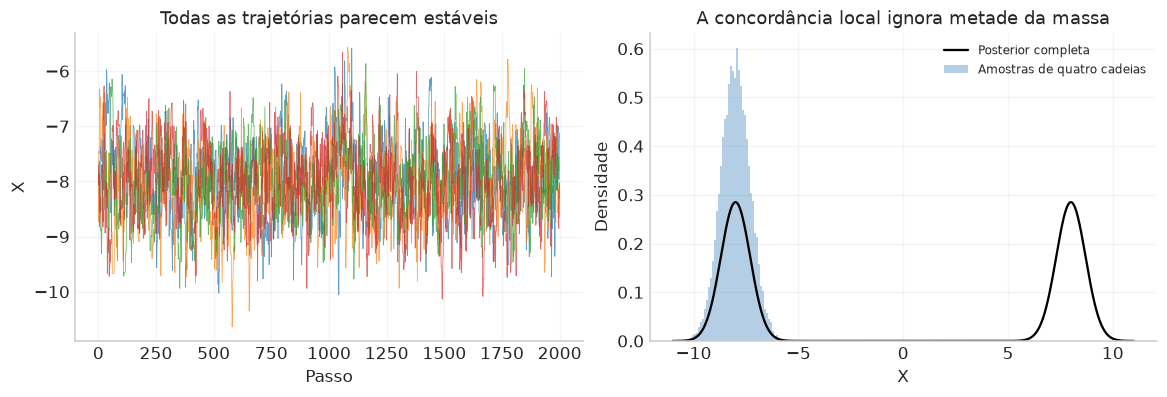

,Inicialização,R clássico,R rank/split/folded,Média amostral,Variância interna s²
0,Todas no modo esquerdo,1.00055,1.00131,-7.99251,0.48769
1,Metade em cada modo,13.25711,1.73445,-0.00489,0.48717


In [19]:
def log_separada(v):
    a=np.asarray(v)[0]
    return np.logaddexp(-.5*((a+8)/.7)**2,-.5*((a-8)/.7)**2)-np.log(2*.7*np.sqrt(2*np.pi))
mesmo=np.array([metropolis(log_separada,[-8.+.1*j],8000,escala=.6,seed=2100+j)['chain'][:,0] for j in range(4)])
dispersas=np.array([metropolis(log_separada,[a],8000,escala=.6,seed=2110+j)['chain'][:,0] for j,a in enumerate([-8.,-8.,8.,8.])])
reg=[]
for lab,c in [('Todas no modo esquerdo',mesmo),('Metade em cada modo',dispersas)]:
    r=gelman_rubin(c[:,1000:]);reg.append({'Inicialização':lab,'R clássico':r['R'],
        'R rank/split/folded':rhat_rank_split(c[:,1000:]),'Média amostral':c[:,1000:].mean(),'Variância interna s²':r['s2']})
fig,ax=plt.subplots(1,2,figsize=(10.5,3.5),constrained_layout=True)
for c in mesmo:ax[0].plot(c[:2000],lw=.5,alpha=.7)
ax[0].set(xlabel='Passo',ylabel='X',title='Todas as trajetórias parecem estáveis')
xx=np.linspace(-11,11,800)
ax[1].plot(xx,.5*stats.norm.pdf(xx,-8,.7)+.5*stats.norm.pdf(xx,8,.7),color='black',label='Posterior completa')
ax[1].hist(mesmo[:,1000:].ravel(),bins=50,density=True,color=AZUL,alpha=.35,label='Amostras de quatro cadeias')
ax[1].set(xlabel='X',ylabel='Densidade',title='A concordância local ignora metade da massa');ax[1].legend(fontsize=8)
figura(fig,'18_gelman_rubin_modos_ocultos')
tabela(pd.DataFrame(reg),'gelman_rubin_modos')

## 11. Simulated tempering: ampliar o espaço para cruzar barreiras

A posterior fria é $\pi_1(\theta)\propto p(\theta)\mathcal L(\theta)$. Nos slides, a família temperada conserva a prior:
$$
\pi_\beta(\theta)=\frac{p(\theta)\mathcal L(\theta)^\beta}{Z_\beta},
\qquad0\leq\beta\leq1,\quad T=1/\beta.
$$
$\beta=1$ é o alvo original. Diminuir $\beta$ atenua a diferença de log-likelihood entre regiões: $\Delta\log\mathcal L$ passa a $\beta\Delta\log\mathcal L$. Barreiras que impediam saltos tornam-se mais fáceis de atravessar. Em $\beta=0$, recuperamos a prior, desde que ela seja própria.

A analogia termodinâmica é direta: para $U(\theta)=-\log\mathcal L(\theta)$, a densidade é $p(\theta)e^{-\beta U(\theta)}/Z_\beta$. $Z_\beta$ funciona como uma função de partição.

### 11.1 Construir um verdadeiro simulated tempering

Introduzimos um índice discreto $k$ para uma escada de temperaturas $\beta_k$. Uma única cadeia evolui no espaço ampliado $(\theta,k)$, com alvo
$$
\widetilde\Pi(\theta,k)=e^{g_k}p(\theta)\mathcal L(\theta)^{\beta_k}.
$$
Podemos alternar duas atualizações:

- **Mover $\theta$ mantendo $k$:** aplicar MH à densidade $p(\theta)\mathcal L(\theta)^{\beta_k}$.
- **Mover $k$ mantendo $\theta$:** propor um índice $j$ e aceitar com
$$
\alpha_{k\to j}=\min\left[1,
 e^{g_j-g_k}\mathcal L(\theta)^{\beta_j-\beta_k}
 \frac{q(k\mid j)}{q(j\mid k)}\right].
$$
A prior cancela nessa mudança de temperatura porque o parâmetro fica fixo. A probabilidade marginal de uma temperatura é proporcional a $e^{g_k}Z_{\beta_k}$. Escolher $g_k=-\log Z_{\beta_k}$ torna as temperaturas equiprováveis.

Os $Z_\beta$ são geralmente desconhecidos. Estimá-los ou ajustar os pesos em uma fase piloto é parte do trabalho de implementar simulated tempering. **Neste exemplo 1D**, a quadratura calcula esses números com precisão e permite demonstrar o algoritmo sem esconder essa dificuldade. Fixaremos os pesos durante a produção.

Para a mistura separada anterior, adotamos prior uniforme em $[-12,12]$ e likelihood igual à soma gaussiana. A restrição de prior é explícita em todas as temperaturas. A marginal condicionada em $\beta=1$ é a posterior desejada; os pontos quentes ajudam na exploração e recebem outro tratamento se quisermos usá-los em inferência.

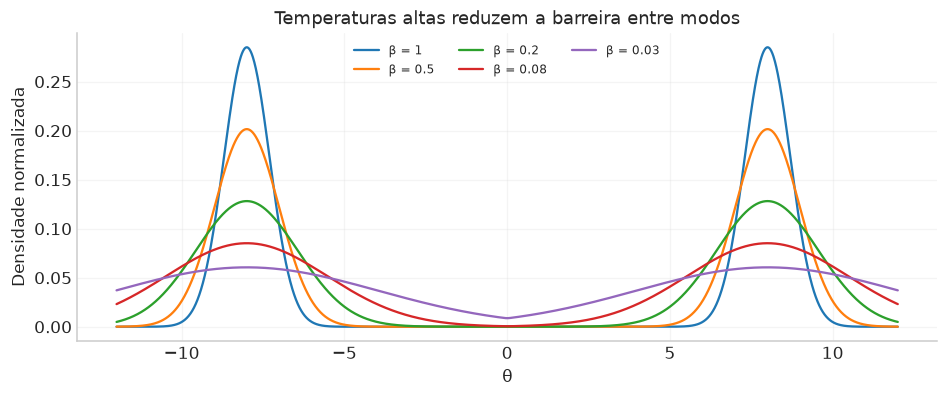

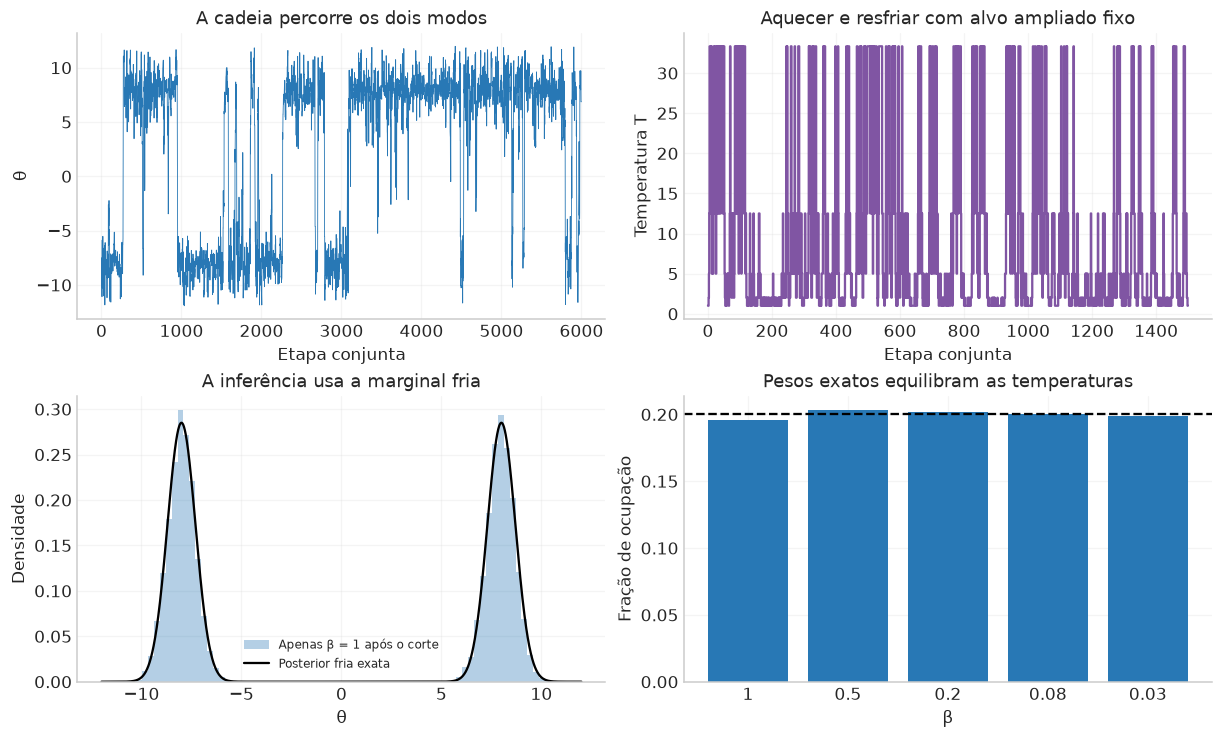

,Método,Estados utilizados,Fração θ < 0,Média amostral
0,MH local frio,65000,1.00000,-7.99629
1,ST: pontos frios,12741,0.50498,-0.09697


Probabilidade fria exata de θ < 0: 0.50000.
Aceitação em θ: 71.9%; aceitação nas propostas de temperatura: 65.5%.


In [20]:
betas=np.array([1.,.5,.2,.08,.03])
def logL_sep_scalar(a):
    return np.logaddexp(-.5*((a+8)/.7)**2,-.5*((a-8)/.7)**2)-np.log(2*.7*np.sqrt(2*np.pi))
Zbeta=np.array([integrate.quad(lambda a:np.exp(be*logL_sep_scalar(a))/24,-12,12,
    points=[-8,0,8],epsabs=1e-10)[0] for be in betas])
gtemp=-np.log(Zbeta)
fig,ax=plt.subplots(figsize=(8.5,3.5),constrained_layout=True)
xs=np.linspace(-12,12,2201)
for be,zbe in zip(betas,Zbeta):ax.plot(xs,np.exp(be*logL_sep_scalar(xs))/(24*zbe),label=f'β = {be:g}')
ax.set(xlabel='θ',ylabel='Densidade normalizada',title='Temperaturas altas reduzem a barreira entre modos');ax.legend(ncol=3,fontsize=8)
figura(fig,'19_temperaturas_distribuicoes')

def simulated_tempering(n=70000,seed=2201):
    rng=np.random.default_rng(seed);theta=-8.;k=0;ll=logL_sep_scalar(theta)
    valores=np.empty(n);indices=np.empty(n,dtype=int);a_theta=0;a_temp=0;tent_temp=0
    for t in range(n):
        cand=theta+rng.normal(0,min(4.,.65/np.sqrt(betas[k])))
        if -12<cand<12:
            lc=logL_sep_scalar(cand)
            if np.log(rng.random())<min(0.,betas[k]*(lc-ll)):
                theta=cand;ll=lc;a_theta+=1
        # Propor ±1 com probabilidade 1/2; propostas fora da escada são permanências.
        j=k+rng.choice([-1,1]);tent_temp+=1
        if 0<=j<len(betas):
            logr=gtemp[j]-gtemp[k]+(betas[j]-betas[k])*ll
            if np.log(rng.random())<min(0.,logr):k=j;a_temp+=1
        valores[t]=theta;indices[t]=k
    return valores,indices,a_theta/n,a_temp/tent_temp
st_values,st_indices,acc_st,acc_temp=simulated_tempering()
st_burn=5000;cold=st_values[st_burn:][st_indices[st_burn:]==0]
plain=metropolis(lambda a:logL_sep_scalar(a[0]) if abs(a[0])<12 else -np.inf,
    [-8.],len(st_values),escala=.65,seed=2202)['chain'][:,0]
fig,ax=plt.subplots(2,2,figsize=(11,6.6),constrained_layout=True)
ax[0,0].plot(st_values[:6000],lw=.55,color=AZUL);ax[0,0].set(xlabel='Etapa conjunta',ylabel='θ',title='A cadeia percorre os dois modos')
ax[0,1].step(np.arange(1500),1/betas[st_indices[:1500]],where='post',color=ROXO)
ax[0,1].set(xlabel='Etapa conjunta',ylabel='Temperatura T',title='Aquecer e resfriar com alvo ampliado fixo')
ax[1,0].hist(cold,bins=70,density=True,alpha=.35,color=AZUL,label='Apenas β = 1 após o corte')
ax[1,0].plot(xs,np.exp(logL_sep_scalar(xs))/(24*Zbeta[0]),color='black',label='Posterior fria exata')
ax[1,0].set(xlabel='θ',ylabel='Densidade',title='A inferência usa a marginal fria');ax[1,0].legend(fontsize=8)
ax[1,1].bar(np.arange(len(betas)),np.bincount(st_indices[st_burn:],minlength=len(betas))/len(st_indices[st_burn:]),color=AZUL)
ax[1,1].axhline(1/len(betas),color='black',ls='--');ax[1,1].set(xticks=np.arange(len(betas)),xticklabels=[f'{b:g}' for b in betas],xlabel='β',ylabel='Fração de ocupação',title='Pesos exatos equilibram as temperaturas')
figura(fig,'20_simulated_tempering')
P_esq_exato=integrate.quad(lambda a:np.exp(logL_sep_scalar(a))/24,-12,0)[0]/Zbeta[0]
tabela(pd.DataFrame({'Método':['MH local frio','ST: pontos frios'],'Estados utilizados':[len(plain)-st_burn,len(cold)],
    'Fração θ < 0':[(plain[st_burn:]<0).mean(),(cold<0).mean()],
    'Média amostral':[plain[st_burn:].mean(),cold.mean()]}),'tempering_modos')
print(f'Probabilidade fria exata de θ < 0: {P_esq_exato:.5f}.')
print(f'Aceitação em θ: {acc_st:.1%}; aceitação nas propostas de temperatura: {acc_temp:.1%}.')
verificar('ST visita os dois modos no ramo frio',np.any(cold<0) and np.any(cold>0))
verificar('ST recupera pesos dos modos em precisão didática',abs((cold<0).mean()-.5)<.15)

A ocupação perto de 50% em cada lado é uma verificação contra a solução conhecida. Os pontos frios continuam correlacionados, e uma aplicação sem solução analítica exigiria execuções independentes e diagnósticos também para a circulação entre temperaturas e entre modos.

### 11.2 Annealing, simulated tempering e parallel tempering

| Método | Estado e objetivo | Papel da temperatura |
|---|---|---|
| Simulated annealing | Buscar bons candidatos a um ótimo | Calendário externo geralmente decrescente |
| Simulated tempering | Amostrar $(\theta,k)$ com alvo ampliado fixo | Uma cadeia muda de temperatura por passos MH |
| Parallel tempering | Amostrar várias réplicas, uma em cada temperatura | Réplicas evoluem e propõem trocas de estados |

No parallel tempering, o alvo conjunto é $\prod_k\pi_{\beta_k}(\theta_k)$. Uma troca entre réplicas $i,j$, proposta simetricamente, tem
$$
\alpha_{\rm swap}=\min\left[1,
\exp\{(\beta_i-\beta_j)[\log\mathcal L(\theta_j)-\log\mathcal L(\theta_i)]\}\right].
$$
A expressão vem da razão entre o produto das densidades após e antes da troca; priors e constantes de normalização cancelam. É uma alternativa que evita estimar os pesos $g_k$ para equilibrar uma única cadeia entre temperaturas. A implementação acima é **simulated tempering**, e a tabela permite distingui-la de suas alternativas.

O aumento de temperatura muda as massas relativas e a dispersão das distribuições quentes. Concatenar diretamente todos os pontos como se fossem da posterior fria mudaria o alvo. A relação $d\log Z_\beta/d\beta=\mathbb E_{\pi_\beta}[\log\mathcal L]$, obtida derivando a integral de $Z_\beta$, motiva a integração termodinâmica para evidências; seu desenvolvimento fica para o estudo de comparação de modelos.

## 12. Conectar a implementação manual às aulas práticas

Conferimos as versões do repositório **Analise_Bayesiana**, no commit `d4a070d6c046a6ef7dbfe0745676bad98e27c4f6`:

- `notebooks/aulas_praticas/02_Grid_Method.ipynb`: avaliação em malha, limiares por massa integrada, interpolação e marginalização em uma terceira variável.
- `notebooks/aulas_praticas/01_Pratica.ipynb`: caminhada aleatória, Metropolis–Hastings, Cobaya em uma gaussiana correlacionada, emcee em uma posterior multimodal e preparação de um exemplo de supernovas.

O objetivo aqui é **entender o que cada componente do pacote realiza a partir das contas já estudadas**. Os exemplos essenciais foram reimplementados neste arquivo; as células seguintes acrescentam os pacotes quando disponíveis. A consulta ao repositório foi somente de leitura.

### 12.1 O que o grid da prática já nos ensinou?

A forma curva do primeiro exemplo é a mesma da seção 1.1. A prática encontra um corte de densidade pelo qual a integral acima do corte atinge uma probabilidade desejada. Ordenar células por densidade e somar suas massas é outra implementação da mesma definição HPD.

Se houver uma terceira variável $w$, a marginal é $p(x,y\mid D)=\int p(x,y,w\mid D)dw$. A integral amplia as possibilidades de $w$ compatíveis com cada par $(x,y)$; um corte em $w=0$ responde à pergunta condicional. Um máximo interpolado continua sendo um ponto, e as massas integradas continuam exigindo a integração apropriada.

O tamanho de cada célula deve acompanhar a resolução: em uma malha uniforme, o fator comum pode cancelar numa razão de massas; em uma malha irregular ou ao calcular normalizações absolutas, os pesos são essenciais. Refinar a grade e ampliar o domínio são verificações diferentes.

### 12.2 Cobaya: a mesma posterior com gerenciamento de parâmetros e propostas

A prática define $\mu=(0{,}5,-1)$, $C=\begin{pmatrix}1&0{,}9\\0{,}9&1\end{pmatrix}$ e
$$
\log\mathcal L(x,y)=-\tfrac12[(x,y)-\mu]^TC^{-1}[(x,y)-\mu].
$$
Com priors uniformes em $[-10,10]^2$, a posterior é essa gaussiana truncada, com efeito de bordas desprezível neste exemplo.

| Campo | Papel na inferência |
|---|---|
| `likelihood` | Função que devolve a log-likelihood |
| `params.prior` | Suporte e densidade prévia dos parâmetros |
| `params.ref` | Distribuição ou valor de inicialização; tem papel distinto da prior |
| `proposal` / `covmat` | Escalas iniciais / covariância para orientar propostas |
| `learn_proposal` | Adaptação da covariância da proposta |
| `Rminus1_stop` | Critério interno de parada baseado na concordância de cadeias ou segmentos |
| `max_samples` | Limite operacional de amostragem; atingir o limite pede avaliar a convergência |

A documentação descreve a proposta do sampler como uma mistura gaussiana/exponencial em direções escolhidas pelo método, com aprendizado e possível organização em blocos. O algoritmo manual de proposta gaussiana fixa é uma referência para entender esses componentes, sem reproduzir todos os detalhes internos do pacote.

O $R-1$ interno do Cobaya é uma generalização descrita por Lewis (2013), e **não é numericamente o mesmo diagnóstico escalar clássico ou rank-normalizado** deste notebook. Em uma execução única, o programa usa segmentos como recurso de diagnóstico, enquanto cadeias independentes iniciadas de maneira dispersa fornecem informação adicional. A opção `temperature` do Cobaya aquece a posterior inteira, $p^{1/T}$; a construção dos slides aquece a likelihood mantendo a prior. Essas convenções coincidem quanto à forma em uma prior plana no suporte fixo, e diferem para uma prior informativa.

In [21]:
# Blocos opcionais; o núcleo do notebook já foi executado sem depender deles.
USAR_COBAYA=importlib.util.find_spec('cobaya') is not None
USAR_EMCEE=importlib.util.find_spec('emcee') is not None
print('Cobaya disponível:',USAR_COBAYA,'; emcee disponível:',USAR_EMCEE)
print('Dependências opcionais, quando necessárias: %pip install cobaya emcee getdist')

Cobaya disponível: True ; emcee disponível: True
Dependências opcionais, quando necessárias: %pip install cobaya emcee getdist


[gauss] Initialized external likelihood.
[mcmc] *WARNING* This run has been SEEDED with seed 2301
[mcmc] Getting initial point... (this may take a few seconds)
[mcmc] Initial point: x:5, y:5
[model] Measuring speeds... (this may take a few seconds)
[model] Setting measured speeds (per sec): {gauss: 63400.0}
[mcmc] Covariance matrix not present. We will start learning the covariance of the proposal earlier: R-1 = 30 (would be 2 if all params loaded).
[mcmc] Sampling!
[mcmc] Progress @ 2026-11-09 18:31:49 : 1 steps taken, and 0 accepted.
[mcmc] Learn + convergence test @ 80 samples accepted.
[mcmc]  - Acceptance rate: 0.305
[mcmc]  - Convergence of means: R-1 = 1.743177 after 64 accepted steps
[mcmc]  - Updated covariance matrix of proposal pdf.
[mcmc] Learn + convergence test @ 160 samples accepted.
[mcmc]  - Acceptance rate: 0.304
[mcmc]  - Convergence of means: R-1 = 0.197376 after 128 accepted steps
[mcmc]  - Updated covariance matrix of proposal pdf.
[mcmc] Learn + convergence test 

,Parâmetro,Média MCMC,Média alvo,Desvio MCMC,Desvio alvo,MCSE estimado da média
0,x,0.60149,0.5,1.00046,1.0,0.04874
1,y,-0.89320,-1.0,0.98810,1.0,0.04959


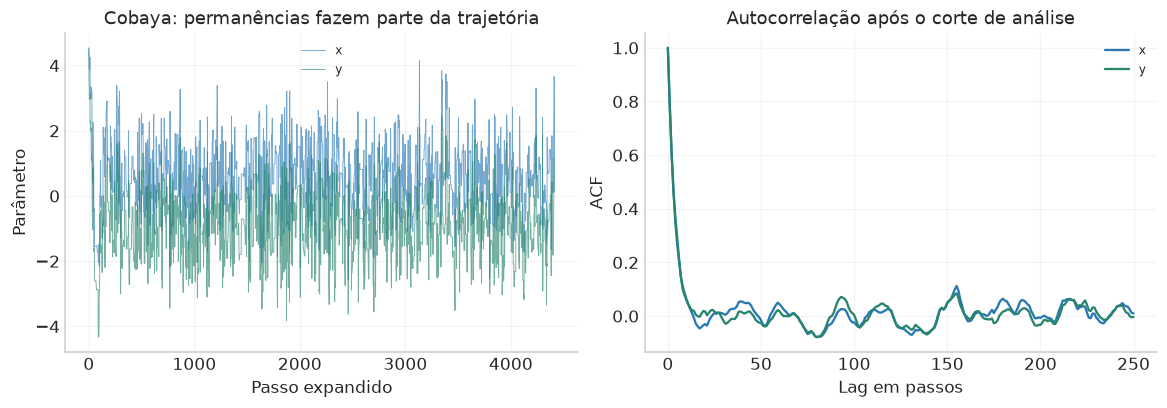

,N,timestamp,acceptance_rate,Rminus1,Rminus1_cl
13,832.0,2026-11-09T18:31:49.845348,0.319386,0.012046,NaN
14,896.0,2026-11-09T18:31:49.891014,0.31274,0.008689,NaN
15,960.0,2026-11-09T18:31:49.928103,0.314033,0.011743,NaN
16,1024.0,2026-11-09T18:31:49.967148,0.31315,0.00801,NaN
17,1088.0,2026-11-09T18:31:50.012065,0.307171,0.006344,0.113851


Cobaya: 3.6.2 ; linhas comprimidas: 1360 ; passos expandidos: 4414


In [22]:
cobaya_result=None
if USAR_COBAYA:
    import cobaya
    from cobaya.run import run
    mean_cb=np.array([.5,-1.]);cov_cb=np.array([[1.,.9],[.9,1.]]);icov_cb=np.linalg.inv(cov_cb)
    def loglike_cb(x,y):
        v=np.array([x,y])-mean_cb;return -.5*v@icov_cb@v
    info_cb={
        'likelihood':{'gauss':loglike_cb},
        'params':{
            'x':{'prior':{'min':-10,'max':10},'ref':5.,'proposal':.5,'latex':'x'},
            'y':{'prior':{'min':-10,'max':10},'ref':5.,'proposal':.5,'latex':'y'}},
        'sampler':{'mcmc':{'learn_proposal':True,'Rminus1_stop':.01,
            'max_samples':12000,'seed':2301,'max_tries':10000}},
        'output':None,'debug':False}
    # output=None conserva os resultados em memória e evita sobrescrever arquivos da prática.
    updated_cb,sampler_cb=run(info_cb)
    df_cb=sampler_cb.products()['sample'].data.copy()
    pesos_cb=df_cb['weight'].to_numpy()
    if not np.allclose(pesos_cb,np.round(pesos_cb)):
        raise ValueError('A expansão temporal abaixo exige pesos inteiros de permanência.')
    chain_cb=np.repeat(df_cb[['x','y']].to_numpy(),np.round(pesos_cb).astype(int),axis=0)
    cb_burn=int(.3*len(chain_cb));cb_ret=chain_cb[cb_burn:]
    cobaya_result={'version':cobaya.__version__,'mean':cb_ret.mean(axis=0),'cov':np.cov(cb_ret.T)}
    tabela(pd.DataFrame({'Parâmetro':['x','y'],'Média MCMC':cb_ret.mean(axis=0),'Média alvo':mean_cb,
        'Desvio MCMC':cb_ret.std(axis=0,ddof=1),'Desvio alvo':np.sqrt(np.diag(cov_cb)),
        'MCSE estimado da média':[cb_ret[:,j].std(ddof=1)*np.sqrt(tau_integrado(cb_ret[:,j])[0]/len(cb_ret)) for j in range(2)]}),'cobaya_resumo')
    fig,ax=plt.subplots(1,2,figsize=(10.5,3.6),constrained_layout=True)
    for j,cor in [(0,AZUL),(1,VERDE)]:
        ax[0].plot(chain_cb[:min(len(chain_cb),8000),j],color=cor,alpha=.65,lw=.6,label=['x','y'][j])
        rho=acf_fft(cb_ret[:,j],250);ax[1].plot(rho,color=cor,label=['x','y'][j])
    ax[0].set(xlabel='Passo expandido',ylabel='Parâmetro',title='Cobaya: permanências fazem parte da trajetória');ax[0].legend(fontsize=8)
    ax[1].set(xlabel='Lag em passos',ylabel='ACF',title='Autocorrelação após o corte de análise');ax[1].legend(fontsize=8)
    figura(fig,'21_cobaya_pratica')
    progress_cb=sampler_cb.products().get('progress')
    if progress_cb is not None:display(progress_cb.tail())
    print('Cobaya:',cobaya.__version__,'; linhas comprimidas:',len(df_cb),'; passos expandidos:',len(chain_cb))
else:
    print('Para executar este complemento, instale cobaya. Toda a análise manual permanece disponível acima.')

Os pesos inteiros do exemplo a temperatura 1 contam permanências nos estados guardados. Para médias e histogramas, usar os pesos ou expandir os estados produz a mesma conta; para a ACF em passos, a sequência expandida deixa a escala explícita. A razão “linhas divididas pela soma dos pesos” é uma medida aproximada da fração de estados aceitos nessa saída, condicionada às convenções de descarte e armazenamento do programa.

Priorizamos a comparação com a média e a covariância conhecidas e mostramos o relatório interno quando disponível. O desvio padrão da distribuição e o MCSE da média são quantidades distintas: o primeiro descreve a largura da posterior; o segundo, a precisão numérica com que estimamos sua média. Diferenças entre a média amostral e o valor exato devem ser avaliadas nessa escala de Monte Carlo. `max_samples` e o corte de 30% usados aqui são escolhas de execução didática; os diagnósticos e a referência analítica permitem avaliá-las. Em um problema desconhecido, executamos várias cadeias e avaliamos precisão, caudas e modos.

### 12.3 emcee: uma população de walkers como estado ampliado

Na prática, a distribuição de dois parâmetros é o produto de duas misturas 1D:
$$
\pi(x,y)=\prod_{j\in\{x,y\}}
\left[\tfrac12\mathcal N(j;2,1)+\tfrac12\mathcal N(j;-2,1)\right].
$$
Ela tem **quatro modos**, em $(\pm2,\pm2)$, enquanto o exemplo do slide 75 tem dois componentes gaussianos. O logaritmo é uma soma de `logaddexp`, o que calcula a soma das densidades de forma estável.

O estado completo do *ensemble sampler* contém $K$ walkers e tem distribuição alvo $\prod_{k=1}^K\pi(X_k)$. No *stretch move*, escolhemos outro walker $X_j$, sorteamos $z\propto z^{-1/2}$ em $[1/a,a]$ e propomos
$$
Y=X_j+z(X_k-X_j),\qquad
\alpha=\min[1,z^{d-1}\pi(Y)/\pi(X_k)].
$$
A razão inclui o fator geométrico do movimento no espaço ampliado. A proposta usa a posição dos demais walkers para acompanhar transformações afins, reduzindo a necessidade de ajustar uma covariância fixa. A geometria não linear e os modos separados continuam importantes.

**Os walkers de um mesmo ensemble interagem.** Para Gelman–Rubin, usamos execuções independentes do ensemble, com inicializações distintas, em vez de tratar cada walker como uma cadeia independente. Para estudar autocorrelação, conservamos o eixo temporal de cada walker; achatar todos os walkers antes de calcular uma ACF mistura dois índices diferentes.

,Parâmetro,Média amostral,Média exata,Variância amostral,Variância exata,τ estimado,Passos retidos por walker / τ,ESS aproximado do ensemble
0,x,0.045,0.0,5.029,5.0,62.191,64.318,2058.186
1,y,-0.015,0.0,4.960,5.0,57.293,69.817,2234.142


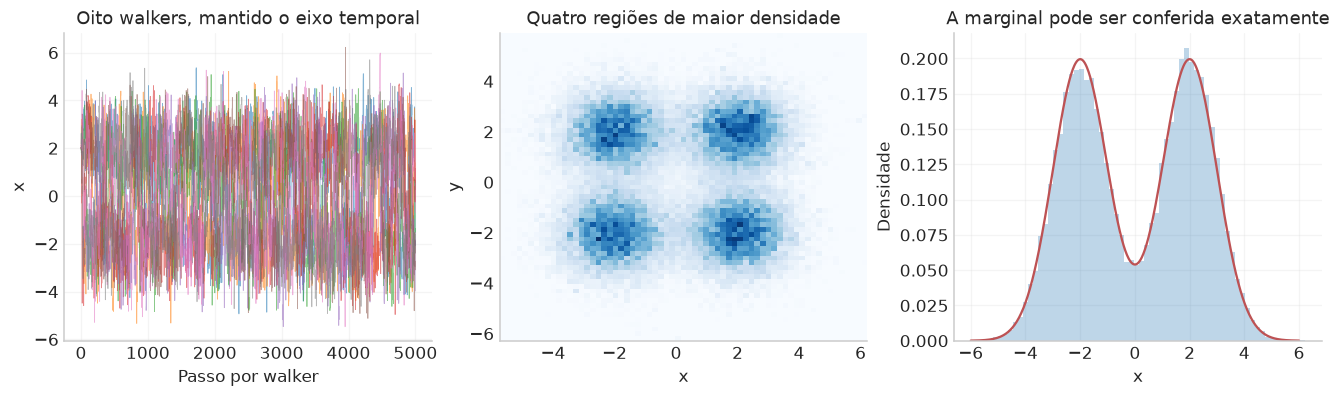

emcee: 3.1.6 ; aceitação média: 0.576


In [23]:
emcee_result=None
if USAR_EMCEE:
    import emcee
    def logprob_emcee(v):
        a=np.asarray(v)
        return float(np.sum(np.logaddexp(-.5*(a-2)**2,-.5*(a+2)**2)-.5*np.log(2*np.pi)-np.log(2)))
    rng_em=np.random.default_rng(2302);nwalkers=32;nsteps_em=5000
    p0=np.array([2.,2.])+.1*rng_em.normal(size=(nwalkers,2))
    sampler_em=emcee.EnsembleSampler(nwalkers,2,logprob_emcee)
    sampler_em.random_state=np.random.RandomState(2303).get_state()
    sampler_em.run_mcmc(p0,nsteps_em,progress=False)
    chains_em=sampler_em.get_chain();burn_em=1000;ret_em=chains_em[burn_em:]
    tau_em=sampler_em.get_autocorr_time(discard=burn_em,tol=0)
    # tol=0 solicita a estimativa mesmo se a cadeia for curta: exibir também comprimento/τ.
    resumo_em=pd.DataFrame({'Parâmetro':['x','y'],'Média amostral':ret_em.mean(axis=(0,1)),
        'Média exata':[0.,0.],'Variância amostral':ret_em.var(axis=(0,1)),'Variância exata':[5.,5.],
        'τ estimado':tau_em,'Passos retidos por walker / τ':len(ret_em)/tau_em,
        'ESS aproximado do ensemble':len(ret_em)*nwalkers/tau_em})
    tabela(resumo_em,'emcee_resumo',casas=3)
    emcee_result={'version':emcee.__version__,'tau':tau_em,'steps_over_tau':len(ret_em)/tau_em}
    fig,ax=plt.subplots(1,3,figsize=(12,3.5),constrained_layout=True)
    ax[0].plot(chains_em[:,:8,0],lw=.5,alpha=.55);ax[0].set(xlabel='Passo por walker',ylabel='x',title='Oito walkers, mantido o eixo temporal')
    flat_em=ret_em.reshape(-1,2);ax[1].hist2d(flat_em[:,0],flat_em[:,1],bins=65,cmap='Blues');ax[1].set(xlabel='x',ylabel='y',title='Quatro regiões de maior densidade')
    vv=np.linspace(-6,6,600);dens=.5*stats.norm.pdf(vv,2,1)+.5*stats.norm.pdf(vv,-2,1)
    ax[2].hist(flat_em[:,0],bins=65,density=True,alpha=.3,color=AZUL);ax[2].plot(vv,dens,color=VERMELHO)
    ax[2].set(xlabel='x',ylabel='Densidade',title='A marginal pode ser conferida exatamente')
    figura(fig,'22_emcee_pratica')
    print('emcee:',emcee.__version__,'; aceitação média:',round(sampler_em.acceptance_fraction.mean(),3))
else:
    print('Instale emcee para executar este complemento; sua distribuição alvo está completamente definida acima.')

O ESS apresentado para o ensemble é uma estimativa prática baseada no tempo integrado calculado pelo pacote; a dependência entre walkers e a exploração global também precisam ser consideradas. A documentação discute o comprimento de cada trajetória em unidades de $\tau$ como uma conferência de estabilidade da estimativa. Um valor como $50\tau$ é uma referência operacional, com alcance dependente do problema e da quantidade calculada.

A opção `tol=0` acima permite ver a estimativa e seu comprimento relativo, em vez de interromper a demonstração. Ela **não certifica convergência**. Se os modos estiverem mais separados, vale comparar inicializações dispersas, várias execuções independentes e alternativas de movimento, como os `DEMove` e `DESnookerMove` já presentes na prática.



### 12.4 Como a física reaparece na prática de supernovas?

No fechamento da prática, a previsão é o módulo de distância de um modelo cosmológico:
$$
\mu_{\rm th}(z;\theta)=5\log_{10}[D_L(z;\theta)/{\rm Mpc}]+25,
\qquad\theta=(\Omega_m,\Omega_\Lambda,H_0).
$$
Com vetor observado $D$, resíduos $r=D-\mu_{\rm th}(\theta)$ e covariância fixa $E$, a função passada ao sampler é
$$
\log\mathcal L(\theta)=-\tfrac12r^TE^{-1}r+\text{constante}.
$$
O fluxo é o mesmo dos exemplos pequenos: definir a previsão física, atribuir likelihood e priors, escolher o algoritmo e conferir a exploração. Calcular distâncias cosmológicas torna a avaliação mais cara, aumentando o valor de propostas eficientes e de controle do número de avaliações.

O exercício de supernovas envolve arquivos externos e detalhes de calibração, cortes e convenções de covariância; mantemos sua aplicação completa no notebook da prática. Na versão de `mymodule.py` consultada, a função monta `dictfinal` e termina sem `return dictfinal`; a chamada do notebook precisa desse retorno para receber o dicionário. Além disso, o uso de módulos de distância já calibrados e de uma covariância fornecida para outra variável exige conferir as convenções da análise original. A posterior cosmológica deve ser fundamentada nesses detalhes antes de interpretar seus parâmetros. Esta observação é uma nota de leitura; o repositório permanece inalterado.

## 13. O que deve ficar consolidado

| Etapa | Pergunta que a orienta | Evidência prática no notebook |
|---|---|---|
| Construir o alvo | Quais dados, hipótese de erro, prior e suporte estamos usando? | RC gaussiano, Poisson dada, misturas e família temperada |
| Otimizar | Que máximo a rotina encontrou e como depende do início? | Vales locais, annealing, genético e LM |
| Definir a dinâmica | Qual proposta e qual regra mantêm o alvo estacionário? | Kernel completo, permanência e balanço detalhado |
| Avaliar o início | Quanto da inicialização ainda aparece? | Relaxação AR(1), trajetórias e cortes explícitos |
| Medir eficiência | Quantas amostras efetivamente informam cada estimativa? | ACF, $\tau_{\rm int}$, ESS e MCSE |
| Diagnosticar exploração | Cadeias independentes concordam e visitam os modos? | Evolução de $s^2$, $\Sigma^2$, $V$, $R^2$ e falso conforto local |
| Lidar com barreiras | O algoritmo consegue circular entre regiões separadas? | Simulated tempering e marginal fria |
| Usar pacotes | Como o código implementa esses componentes? | Cobaya e emcee com alvos verificáveis |

As médias e histogramas da MCMC calculam integrais da posterior. A evidência continua exigindo outro tratamento, como a integração explícita, nested sampling ou integração termodinâmica. A otimização fornece pontos de referência e inicializações úteis; caracterizar as incertezas exige explorar a distribuição.
